
# Direct Neural Population Geometry from Raw Spike Counts

## Experiment 1 — Static Population Representation

**Project:** A Number Simplex in the Human Medial Temporal Lobe

### Research question

Can numerical representations (1–9) exhibit a reliable, high-dimensional simplex-like geometry directly from observed neural spike counts, without supervised decoding or Bayesian posterior estimation?

### Method

1. Extract spike counts from a fixed 900 ms window.
2. Construct trial-wise neural population vectors.
3. Compute empirical population centroids for numbers 1–9.
4. Analyze pairwise distances, affine rank, singular values, and simplex volume.
5. Quantify uncertainty using bootstrap resampling.
6. Compare observed geometry against appropriate null models.

### Initial configuration

- Subject: YFU
- Task: Arithmetic
- Analysis window: 50–950 ms after operand onset
- Representation: Raw spike counts
- Temporal binning: None
- Decoder: None
- Dimensionality reduction: None for primary geometric measurements

### Important distinction

An empirical population centroid is the arithmetic mean of observed neural spike-count vectors, not a Bayesian posterior mean.

Nine affinely independent centroids define an eight-dimensional simplex mathematically, but this alone does not establish a meaningful neural simplex representation.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Reproducibility
SEED = 42
rng = np.random.default_rng(SEED)

# Initial experiment
SUBJECT = "YFU"
TASK = "arithmetic"

WINDOW_START_MS = 50
WINDOW_END_MS = 950

NUMBERS = np.arange(1, 10)

print("Subject:", SUBJECT)
print("Task:", TASK)
print("Window:", WINDOW_START_MS, "to", WINDOW_END_MS, "ms")
print("Number labels:", NUMBERS)


Subject: YFU
Task: arithmetic
Window: 50 to 950 ms
Number labels: [1 2 3 4 5 6 7 8 9]


In [2]:

from pathlib import Path

print("Current directory:", Path.cwd())

# Locate YFU data files
for file in Path.cwd().rglob("*YFU*"):
    if file.is_file():
        print(file)


Current directory: c:\Users\shafi\number-simplex-reproduction\notebooks


In [3]:

from pathlib import Path

ROOT = Path.cwd().parent

print("Project root:", ROOT)
print("\nProject folders:")

for item in sorted(ROOT.iterdir()):
    print("📁" if item.is_dir() else "📄", item.name)


Project root: c:\Users\shafi\number-simplex-reproduction

Project folders:
📁 .git
📄 .gitignore
📁 .venv
📁 .venv312
📁 .vscode
📁 data
📁 figures
📁 figures1
📁 notebooks
📁 notebooks1
📁 notes
📄 oct8summary.md
📄 README.md
📁 results
📄 run_lda_vs_logistic_subject.py
📄 run_poisson_population_subject.py
📁 scripts
📁 src
📁 tables
📁 tables1
📄 test_parallel_permutation.py


In [4]:

DATA_DIR = ROOT / "data"

print("Data directory:", DATA_DIR)
print("\nAvailable files:")

for path in sorted(DATA_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(DATA_DIR))


Data directory: c:\Users\shafi\number-simplex-reproduction\data

Available files:
data_summary.md
raw\YFF\.DS_Store
raw\YFF\arithmetic\photoBehavEvents.csv
raw\YFF\arithmetic\photoBehavEvents.mat
raw\YFF\arithmetic\spikes.mat
raw\YFF\dot\photoBehavEvents.mat
raw\YFI\.DS_Store
raw\YFI\arithmetic\photoBehavEvents.csv
raw\YFI\arithmetic\photoBehavEvents.mat
raw\YFI\arithmetic\spikes.mat
raw\YFI\dot\photoBehavEvents.mat
raw\YFI\dot\spikes.mat
raw\YFJ\.DS_Store
raw\YFJ\arithmetic\photoBehavEvents.csv
raw\YFJ\arithmetic\photoBehavEvents.mat
raw\YFJ\arithmetic\spikes.mat
raw\YFJ\dot\photoBehavEvents.mat
raw\YFJ\dot\spikes.mat
raw\YFK\.DS_Store
raw\YFK\arithmetic\photoBehavEvents.csv
raw\YFK\arithmetic\photoBehavEvents.mat
raw\YFK\arithmetic\spikesArithmetic.mat
raw\YFK\dot\photoBehavEvents.mat
raw\YFK\dot\spikesDot.mat
raw\YFL\.DS_Store
raw\YFL\arithmetic\photoBehavEvents.csv
raw\YFL\arithmetic\photoBehavEvents.mat
raw\YFL\arithmetic\spikesArithmetic.mat
raw\YFL\dot\photoBehavEvents.mat
raw\Y

In [5]:

import pandas as pd
from scipy.io import loadmat

# File paths
YFU_DIR = ROOT / "data" / "raw" / "YFU" / "arithmetic"

BEHAV_PATH = YFU_DIR / "photoBehavEvents.csv"
SPIKES_PATH = YFU_DIR / "spikes.mat"

# Load behavioral data
behav = pd.read_csv(BEHAV_PATH)

print("=== BEHAVIORAL DATA ===")
print("Shape:", behav.shape)
print("\nColumns:")
print(behav.columns.tolist())
print("\nFirst 5 rows:")
display(behav.head())

# Inspect MATLAB spike data
spike_data = loadmat(SPIKES_PATH)

print("\n=== SPIKE DATA ===")

for key, value in spike_data.items():
    if not key.startswith("__"):
        print(
            "Variable:", key,
            "| Type:", type(value),
            "| Shape:", getattr(value, "shape", None),
            "| Dtype:", getattr(value, "dtype", None)
        )


=== BEHAVIORAL DATA ===
Shape: (300, 22)

Columns:
['trial', 'tCue1', 'tCue2', 'tCue3', 'presentationEnd', 'tPress1', 'tPress2', 'tPress3', 'keyPress1', 'keyPress2', 'keyPress3', 'choiceEnd', 'timeFeedback', 'cue1', 'cue2', 'operation', 'operationFirst', 'correctAnsw', 'givenAnsw', 'correct', 'correctFb', 'toExclude']

First 5 rows:


,trial,tCue1,tCue2,tCue3,presentationEnd,tPress1,tPress2,tPress3,keyPress1,keyPress2,...,timeFeedback,cue1,cue2,operation,operationFirst,correctAnsw,givenAnsw,correct,correctFb,toExclude
0,1,5910.833333,6660.833333,7410.800000,8177.466667,72843.066667,78309.633333,NaN,Home,5.0,...,80876.233333,7,8,-,1,-1,5,0,1,0
1,2,81376.233333,82126.233333,82876.233333,83626.200000,86309.500000,86642.800000,NaN,1,1.0,...,88376.100000,7,4,+,0,11,11,1,1,0
2,3,88876.133333,89626.100000,90376.100000,91126.066667,94109.366667,NaN,NaN,1,NaN,...,95592.666667,7,6,-,1,1,1,1,1,0
3,4,96092.666667,96842.633333,97592.633333,98342.633333,104792.500000,105425.833333,113942.366667,1,5.0,...,118208.933333,10,5,-,1,5,15,0,1,0
4,5,118708.933333,119458.933333,120208.933333,120958.900000,122258.900000,NaN,NaN,0,NaN,...,123392.200000,8,0,-,0,8,0,0,1,0


NotImplementedError: Please use HDF reader for matlab v7.3 files, e.g. h5py

In [6]:

import h5py

print("h5py version:", h5py.__version__)


ImportError: DLL load failed while importing _npystrings: An Application Control policy has blocked this file.

In [7]:
%pip install h5py

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:

import h5py

print("h5py version:", h5py.__version__)


ImportError: DLL load failed while importing h5d: An Application Control policy has blocked this file.

In [9]:

import sys
import platform
import importlib.metadata

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Architecture:", platform.architecture())
print("h5py version:", importlib.metadata.version("h5py"))
print("NumPy version:", importlib.metadata.version("numpy"))


Python executable: c:\Users\shafi\number-simplex-reproduction\.venv\Scripts\python.exe
Python version: 3.13.15 (tags/v3.13.15:4061bc4, Aug  5 2026, 13:05:39) [MSC v.1944 64 bit (AMD64)]
Architecture: ('64bit', 'WindowsPE')
h5py version: 3.16.0
NumPy version: 2.5.3


In [10]:

print("=== YFU BEHAVIORAL DATA ===")

print("Shape:", behav.shape)

print("\nColumn names:")
print(behav.columns.tolist())

print("\nFirst 5 rows:")
display(behav.head())

print("\nTiming-related columns:")
timing_cols = [
    col for col in behav.columns
    if col.lower().startswith("t")
    or "time" in col.lower()
]

display(behav[timing_cols].head())


=== YFU BEHAVIORAL DATA ===
Shape: (300, 22)

Column names:
['trial', 'tCue1', 'tCue2', 'tCue3', 'presentationEnd', 'tPress1', 'tPress2', 'tPress3', 'keyPress1', 'keyPress2', 'keyPress3', 'choiceEnd', 'timeFeedback', 'cue1', 'cue2', 'operation', 'operationFirst', 'correctAnsw', 'givenAnsw', 'correct', 'correctFb', 'toExclude']

First 5 rows:


,trial,tCue1,tCue2,tCue3,presentationEnd,tPress1,tPress2,tPress3,keyPress1,keyPress2,...,timeFeedback,cue1,cue2,operation,operationFirst,correctAnsw,givenAnsw,correct,correctFb,toExclude
0,1,5910.833333,6660.833333,7410.800000,8177.466667,72843.066667,78309.633333,NaN,Home,5.0,...,80876.233333,7,8,-,1,-1,5,0,1,0
1,2,81376.233333,82126.233333,82876.233333,83626.200000,86309.500000,86642.800000,NaN,1,1.0,...,88376.100000,7,4,+,0,11,11,1,1,0
2,3,88876.133333,89626.100000,90376.100000,91126.066667,94109.366667,NaN,NaN,1,NaN,...,95592.666667,7,6,-,1,1,1,1,1,0
3,4,96092.666667,96842.633333,97592.633333,98342.633333,104792.500000,105425.833333,113942.366667,1,5.0,...,118208.933333,10,5,-,1,5,15,0,1,0
4,5,118708.933333,119458.933333,120208.933333,120958.900000,122258.900000,NaN,NaN,0,NaN,...,123392.200000,8,0,-,0,8,0,0,1,0



Timing-related columns:


,trial,tCue1,tCue2,tCue3,tPress1,tPress2,tPress3,timeFeedback,toExclude
0,1,5910.833333,6660.833333,7410.800000,72843.066667,78309.633333,NaN,80876.233333,0
1,2,81376.233333,82126.233333,82876.233333,86309.500000,86642.800000,NaN,88376.100000,0
2,3,88876.133333,89626.100000,90376.100000,94109.366667,NaN,NaN,95592.666667,0
3,4,96092.666667,96842.633333,97592.633333,104792.500000,105425.833333,113942.366667,118208.933333,0
4,5,118708.933333,119458.933333,120208.933333,122258.900000,NaN,NaN,123392.200000,0


In [11]:

cols = [
    "trial",
    "tCue1",
    "tCue2",
    "tCue3",
    "cue1",
    "cue2",
    "operation",
    "operationFirst",
    "toExclude"
]

display(behav[cols].head(10))

print("\n=== TIMESTAMP RANGES ===")

for col in ["tCue1", "tCue2", "tCue3"]:
    print(
        col,
        "| Min:", behav[col].min(),
        "| Max:", behav[col].max()
    )

print("\n=== OPERAND VALUES ===")
print("cue1:", sorted(behav["cue1"].dropna().unique()))
print("cue2:", sorted(behav["cue2"].dropna().unique()))

print("\n=== EXCLUSION FLAGS ===")
print(behav["toExclude"].value_counts(dropna=False))


,trial,tCue1,tCue2,tCue3,cue1,cue2,operation,operationFirst,toExclude
0,1,5910.833333,6660.833333,7410.800000,7,8,-,1,0
1,2,81376.233333,82126.233333,82876.233333,7,4,+,0,0
2,3,88876.133333,89626.100000,90376.100000,7,6,-,1,0
3,4,96092.666667,96842.633333,97592.633333,10,5,-,1,0
4,5,118708.933333,119458.933333,120208.933333,8,0,-,0,0
5,6,123892.200000,124642.166667,125392.166667,4,4,+,1,0
6,7,129525.433333,130275.433333,131025.400000,10,2,+,1,0
7,8,135025.333333,135775.333333,136525.300000,7,3,-,1,0
8,9,143491.866667,144241.833333,144991.833333,3,2,-,0,0
9,10,148841.766667,149575.100000,150341.733333,4,4,+,0,0



=== TIMESTAMP RANGES ===
tCue1 | Min: 5910.83333333333 | Max: 2267505.73333333
tCue2 | Min: 6660.83333333333 | Max: 2268255.7
tCue3 | Min: 7410.8 | Max: 2269005.7

=== OPERAND VALUES ===
cue1: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
cue2: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]

=== EXCLUSION FLAGS ===
toExclude
0    300
Name: count, dtype: int64


In [12]:

print("=== PRESENTATION ORDER ===")

print("\noperationFirst values:")
print(behav["operationFirst"].value_counts(dropna=False))

print("\nOperation values:")
print(behav["operation"].value_counts(dropna=False))

print("\nExamples by presentation order:")

for order in behav["operationFirst"].dropna().unique():
    print(f"\noperationFirst = {order}")

    subset = behav[
        behav["operationFirst"] == order
    ]

    display(
        subset[
            [
                "trial",
                "cue1",
                "cue2",
                "operation",
                "operationFirst",
                "tCue1",
                "tCue2",
                "tCue3"
            ]
        ].head(5)
    )


=== PRESENTATION ORDER ===

operationFirst values:
operationFirst
0    161
1    139
Name: count, dtype: int64

Operation values:
operation
+    161
-    139
Name: count, dtype: int64

Examples by presentation order:

operationFirst = 1


,trial,cue1,cue2,operation,operationFirst,tCue1,tCue2,tCue3
0,1,7,8,-,1,5910.833333,6660.833333,7410.800000
2,3,7,6,-,1,88876.133333,89626.100000,90376.100000
3,4,10,5,-,1,96092.666667,96842.633333,97592.633333
5,6,4,4,+,1,123892.200000,124642.166667,125392.166667
6,7,10,2,+,1,129525.433333,130275.433333,131025.400000



operationFirst = 0


,trial,cue1,cue2,operation,operationFirst,tCue1,tCue2,tCue3
1,2,7,4,+,0,81376.233333,82126.233333,82876.233333
4,5,8,0,-,0,118708.933333,119458.933333,120208.933333
8,9,3,2,-,0,143491.866667,144241.833333,144991.833333
9,10,4,4,+,0,148841.766667,149575.100000,150341.733333
11,12,7,3,+,0,165208.166667,165958.133333,166708.133333


In [13]:

cols = [
    "trial", "cue1", "cue2",
    "operation", "operationFirst",
    "tCue1", "tCue2", "tCue3"
]

for order in [0, 1]:
    print(f"\n=== operationFirst = {order} ===")

    print(
        behav.loc[
            behav["operationFirst"] == order,
            cols
        ].head(5).to_string(index=False)
    )



=== operationFirst = 0 ===
 trial  cue1  cue2 operation  operationFirst         tCue1         tCue2         tCue3
     2     7     4         +               0  81376.233333  82126.233333  82876.233333
     5     8     0         -               0 118708.933333 119458.933333 120208.933333
     9     3     2         -               0 143491.866667 144241.833333 144991.833333
    10     4     4         +               0 148841.766667 149575.100000 150341.733333
    12     7     3         +               0 165208.166667 165958.133333 166708.133333

=== operationFirst = 1 ===
 trial  cue1  cue2 operation  operationFirst         tCue1         tCue2         tCue3
     1     7     8         -               1   5910.833333   6660.833333   7410.800000
     3     7     6         -               1  88876.133333  89626.100000  90376.100000
     4    10     5         -               1  96092.666667  96842.633333  97592.633333
     6     4     4         +               1 123892.200000 124642.166667 1

In [14]:

from pathlib import Path

SEARCH_DIRS = [
    ROOT / "src",
    ROOT / "scripts"
]

keywords = [
    "operationFirst",
    "tCue1",
    "tCue2",
    "tCue3"
]

for directory in SEARCH_DIRS:
    for file in directory.rglob("*.py"):
        content = file.read_text(
            encoding="utf-8",
            errors="ignore"
        )

        matches = [
            word for word in keywords
            if word in content
        ]

        if matches:
            print(
                file.relative_to(ROOT),
                "| Matches:",
                matches
            )


src\firing_rate_tuning.py | Matches: ['operationFirst', 'tCue1', 'tCue2', 'tCue3']


In [15]:

from pathlib import Path

file_path = ROOT / "src" / "firing_rate_tuning.py"

lines = file_path.read_text(
    encoding="utf-8",
    errors="ignore"
).splitlines()

keywords = [
    "operationFirst",
    "tCue1",
    "tCue2",
    "tCue3"
]

matching_lines = [
    i for i, line in enumerate(lines)
    if any(word in line for word in keywords)
]

shown = set()

for i in matching_lines:
    start = max(0, i - 8)
    end = min(len(lines), i + 12)

    for j in range(start, end):
        if j not in shown:
            print(f"{j+1:4d}: {lines[j]}")
            shown.add(j)

    print("-" * 60)


 104:     # ---------------------------------------------------------
 105: 
 106:     behav = pd.read_csv(behavior_file)
 107: 
 108:     required_columns = [
 109:         "trial",
 110:         "cue1",
 111:         "cue2",
 112:         "operationFirst",
 113:         "tCue1",
 114:         "tCue2",
 115:         "tCue3",
 116:     ]
 117: 
 118:     missing = [
 119:         col for col in required_columns
 120:         if col not in behav.columns
 121:     ]
 122: 
 123:     if missing:
------------------------------------------------------------
 124:         raise ValueError(
------------------------------------------------------------
 125:             f"Missing behavioral columns: {missing}"
------------------------------------------------------------
 126:         )
------------------------------------------------------------
 133: # 3. Determine actual operand onsets
 134: # ---------------------------------------------------------
 135: 
 136:     operand_data = behav[
 13

In [16]:

import numpy as np
import pandas as pd

# Copy behavioral information
operand_data = behav[
    [
        "trial",
        "cue1",
        "cue2",
        "operationFirst",
        "tCue1",
        "tCue2",
        "tCue3"
    ]
].copy()

# Determine operand onset times
operand_data["operand1_onset"] = np.where(
    operand_data["operationFirst"] == 1,
    operand_data["tCue2"],
    operand_data["tCue1"]
)

operand_data["operand2_onset"] = np.where(
    operand_data["operationFirst"] == 1,
    operand_data["tCue3"],
    operand_data["tCue2"]
)

# First operand presentations
op1 = operand_data[
    ["trial", "cue1", "operand1_onset"]
].copy()

op1.columns = ["trial", "number", "onset"]
op1["operand_position"] = 1

# Second operand presentations
op2 = operand_data[
    ["trial", "cue2", "operand2_onset"]
].copy()

op2.columns = ["trial", "number", "onset"]
op2["operand_position"] = 2

# Combine presentations
presentations = pd.concat(
    [op1, op2],
    ignore_index=True
)

# Restrict to numbers 1–9
presentations = presentations[
    presentations["number"].between(1, 9)
].copy()

presentations = presentations.sort_values(
    ["trial", "operand_position"]
).reset_index(drop=True)

print("=== YFU NUMBER PRESENTATIONS ===")
print("Total valid presentations:", len(presentations))

print("\nPresentations per number:")
print(
    presentations["number"]
    .value_counts()
    .sort_index()
)

print("\nFirst 10 presentations:")
display(presentations.head(10))


=== YFU NUMBER PRESENTATIONS ===
Total valid presentations: 494

Presentations per number:
number
1    53
2    67
3    52
4    62
5    51
6    48
7    65
8    49
9    47
Name: count, dtype: int64

First 10 presentations:


,trial,number,onset,operand_position
0,1,7,6660.833333,1
1,1,8,7410.800000,2
2,2,7,81376.233333,1
3,2,4,82126.233333,2
4,3,7,89626.100000,1
5,3,6,90376.100000,2
6,4,5,97592.633333,2
7,5,8,118708.933333,1
8,6,4,124642.166667,1
9,6,4,125392.166667,2


In [17]:

@'
import h5py

path = "data/raw/YFU/arithmetic/spikes.mat"

with h5py.File(path, "r") as f:
    print("=== FILE ATTRIBUTES ===")
    for key, value in f.attrs.items():
        print(key, ":", value)

    print("\n=== SPIKES GROUP ATTRIBUTES ===")
    for key, value in f["spikes"].attrs.items():
        print(key, ":", value)

    print("\n=== MATRIX DIMENSIONS ===")
    jc = f["spikes/jc"]
    ir = f["spikes/ir"]

    print("Neurons:", int(ir[:].max()) + 1)
    print("Time columns:", len(jc) - 1)
    print("Last column pointer:", jc[-1])
'@ | py -3.12 -


SyntaxError: unterminated string literal (detected at line 1) (1449816029.py, line 1)

In [18]:

file_path = ROOT / "src" / "firing_rate_tuning.py"

lines = file_path.read_text(
    encoding="utf-8",
    errors="ignore"
).splitlines()

keywords = [
    "1000",
    "sampling",
    "sample",
    "round(",
    "astype(int)",
    "50",
    "950",
    "onset"
]

for i, line in enumerate(lines):
    if any(word.lower() in line.lower() for word in keywords):
        print(f"{i+1:4d}: {line}")


 129:     # 3. Determine actual operand onsets
 133: # 3. Determine actual operand onsets
 161:         operand_data["operand1_onset"] = operand_data["tCue1"]
 162:         operand_data["operand2_onset"] = operand_data["tCue3"]
 175:         operand_data["operand1_onset"] = np.where(
 181:         operand_data["operand2_onset"] = np.where(
 192:         ["trial", "cue1", "operand1_onset"]
 195:     op1.columns = ["trial", "number", "onset"]
 199:         ["trial", "cue2", "operand2_onset"]
 202:     op2.columns = ["trial", "number", "onset"]
 310:         onset = row["onset"]
 313:         # 0.05 to 0.95 s after operand onset
 314:         window_start = onset + 50
 315:         window_end = onset + 950


In [19]:

file_path = ROOT / "src" / "firing_rate_tuning.py"

lines = file_path.read_text(
    encoding="utf-8",
    errors="ignore"
).splitlines()

for i in range(290, min(345, len(lines))):
    print(f"{i+1:4d}: {lines[i]}")


 291:         )
 292: 
 293:     region = region_names[python_row]
 294: 
 295:     spike_times = (
 296:         spikes_sparse
 297:         .getrow(python_row)
 298:         .nonzero()[1]
 299:     )
 300: 
 301:     # ---------------------------------------------------------
 302:     # 8. Compute firing rate for every presentation
 303:     # ---------------------------------------------------------
 304: 
 305:     firing_rates = []
 306:     spike_counts = []
 307: 
 308:     for _, row in presentations.iterrows():
 309: 
 310:         onset = row["onset"]
 311: 
 312:         # Paper arithmetic window:
 313:         # 0.05 to 0.95 s after operand onset
 314:         window_start = onset + 50
 315:         window_end = onset + 950
 316: 
 317:         count = np.sum(
 318:             (spike_times >= window_start)
 319:             & (spike_times < window_end)
 320:         )
 321: 
 322:         firing_rate = count / 0.9
 323: 
 324:         spike_counts.append(count)
 325:     

In [20]:

EXPORT_DIR = ROOT / "tables1"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

presentations.to_csv(
    EXPORT_DIR / "YFU_arithmetic_presentations.csv",
    index=False
)

print("Saved:", EXPORT_DIR / "YFU_arithmetic_presentations.csv")


Saved: c:\Users\shafi\number-simplex-reproduction\tables1\YFU_arithmetic_presentations.csv


In [21]:

# Load the extracted raw spike counts
COUNT_PATH = (
    ROOT / "tables1" /
    "YFU_arithmetic_raw_spike_counts.csv"
)

X_df = pd.read_csv(COUNT_PATH)
X = X_df.to_numpy()

y = presentations["number"].to_numpy()

print("=== POPULATION MATRIX ===")
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\n=== VALIDATION ===")
print("Missing values:", np.isnan(X).sum())
print("Negative counts:", np.sum(X < 0))
print("Non-integer counts:", np.sum(X != np.floor(X)))
print("Neurons with zero spikes:", np.sum(X.sum(axis=0) == 0))

print("\n=== FIRING RATE SUMMARY ===")
mean_rates = X.mean(axis=0) / 0.9

print("Mean firing rate:", round(mean_rates.mean(), 3), "Hz")
print("Median firing rate:", round(np.median(mean_rates), 3), "Hz")
print("Minimum neuron rate:", round(mean_rates.min(), 3), "Hz")
print("Maximum neuron rate:", round(mean_rates.max(), 3), "Hz")


=== POPULATION MATRIX ===
X shape: (494, 78)
y shape: (494,)

=== VALIDATION ===
Missing values: 0
Negative counts: 0
Non-integer counts: 0
Neurons with zero spikes: 0

=== FIRING RATE SUMMARY ===
Mean firing rate: 8.719 Hz
Median firing rate: 7.497 Hz
Minimum neuron rate: 0.135 Hz
Maximum neuron rate: 36.471 Hz


In [22]:

# Experiment 1A: Direct population centroids

numbers = np.arange(1, 10)

M = np.vstack([
    X[y == k].mean(axis=0)
    for k in numbers
])

print("=== CENTROID MATRIX ===")
print("Shape:", M.shape)

print("\n=== MEAN SPIKE COUNT PER NUMBER ===")
for k, mu in zip(numbers, M):
    print(
        f"Number {k}: "
        f"{mu.mean():.3f} spikes/neuron "
        f"({mu.mean()/0.9:.3f} Hz)"
    )

print("\n=== FIRST FIVE NEURON COORDINATES ===")
centroid_df = pd.DataFrame(
    M,
    index=numbers,
    columns=[f"neuron_{j}" for j in range(X.shape[1])]
)

display(centroid_df.iloc[:, :5].round(3))


=== CENTROID MATRIX ===
Shape: (9, 78)

=== MEAN SPIKE COUNT PER NUMBER ===
Number 1: 7.864 spikes/neuron (8.737 Hz)
Number 2: 7.893 spikes/neuron (8.770 Hz)
Number 3: 7.827 spikes/neuron (8.696 Hz)
Number 4: 7.718 spikes/neuron (8.575 Hz)
Number 5: 8.032 spikes/neuron (8.925 Hz)
Number 6: 7.817 spikes/neuron (8.685 Hz)
Number 7: 7.819 spikes/neuron (8.687 Hz)
Number 8: 7.845 spikes/neuron (8.716 Hz)
Number 9: 7.825 spikes/neuron (8.695 Hz)

=== FIRST FIVE NEURON COORDINATES ===


,neuron_0,neuron_1,neuron_2,neuron_3,neuron_4
1,4.151,13.811,9.038,14.604,0.057
2,4.239,13.881,8.567,14.597,0.134
3,3.615,13.231,8.346,13.981,0.096
4,3.258,13.468,8.855,15.484,0.097
5,4.353,13.588,8.647,15.686,0.078
6,4.229,12.562,8.854,13.750,0.167
7,4.138,13.108,8.446,14.292,0.123
8,3.918,12.327,8.714,14.735,0.224
9,4.000,12.830,8.234,14.319,0.128


In [23]:

from scipy.spatial.distance import pdist, squareform

# Euclidean distances between the 9 centroids
D = squareform(pdist(M, metric="euclidean"))

distance_df = pd.DataFrame(
    D,
    index=numbers,
    columns=numbers
)

print("=== PAIRWISE CENTROID DISTANCES ===")
display(distance_df.round(3))

# Summarize the 36 unique distances
upper = D[np.triu_indices(9, k=1)]

print("\n=== DISTANCE SUMMARY ===")
print("Minimum distance:", round(upper.min(), 3))
print("Maximum distance:", round(upper.max(), 3))
print("Mean distance:", round(upper.mean(), 3))
print("Standard deviation:", round(upper.std(), 3))

# Find closest and farthest number pairs
pairs = np.triu_indices(9, k=1)

closest = np.argmin(upper)
farthest = np.argmax(upper)

print(
    "Closest pair:",
    (numbers[pairs[0][closest]], numbers[pairs[1][closest]])
)

print(
    "Farthest pair:",
    (numbers[pairs[0][farthest]], numbers[pairs[1][farthest]])
)


=== PAIRWISE CENTROID DISTANCES ===


,1,2,3,4,5,6,7,8,9
1,0.000,5.163,5.109,5.648,4.966,4.788,4.234,5.952,5.603
2,5.163,0.000,4.775,4.614,5.124,4.984,4.443,4.512,5.886
3,5.109,4.775,0.000,5.262,5.517,4.544,4.310,5.249,4.622
4,5.648,4.614,5.262,0.000,5.526,5.596,4.658,4.851,6.045
5,4.966,5.124,5.517,5.526,0.000,5.584,4.655,5.284,5.660
6,4.788,4.984,4.544,5.596,5.584,0.000,4.072,5.839,5.405
7,4.234,4.443,4.310,4.658,4.655,4.072,0.000,4.654,4.937
8,5.952,4.512,5.249,4.851,5.284,5.839,4.654,0.000,5.784
9,5.603,5.886,4.622,6.045,5.660,5.405,4.937,5.784,0.000



=== DISTANCE SUMMARY ===
Minimum distance: 4.072
Maximum distance: 6.045
Mean distance: 5.107
Standard deviation: 0.528
Closest pair: (np.int64(6), np.int64(7))
Farthest pair: (np.int64(4), np.int64(9))


=== NUMBER-LINE RELATIONSHIP ===
Pearson correlation: 0.056
Spearman correlation: 0.0077


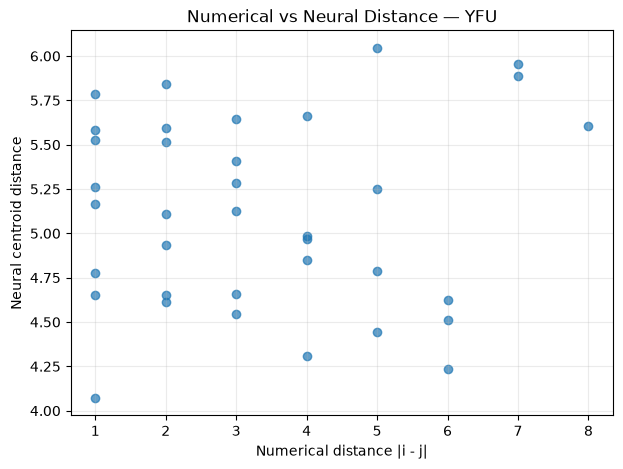

In [24]:

from scipy.stats import spearmanr, pearsonr
import matplotlib.pyplot as plt

# Unique pairs of numbers
i_idx, j_idx = np.triu_indices(9, k=1)

numerical_distance = np.abs(
    numbers[i_idx] - numbers[j_idx]
)

neural_distance = D[i_idx, j_idx]

# Descriptive correlations
pearson_r, _ = pearsonr(
    numerical_distance,
    neural_distance
)

spearman_rho, _ = spearmanr(
    numerical_distance,
    neural_distance
)

print("=== NUMBER-LINE RELATIONSHIP ===")
print("Pearson correlation:", round(pearson_r, 4))
print("Spearman correlation:", round(spearman_rho, 4))

# Plot
plt.figure(figsize=(7, 5))

plt.scatter(
    numerical_distance,
    neural_distance,
    alpha=0.7
)

plt.xlabel("Numerical distance |i - j|")
plt.ylabel("Neural centroid distance")
plt.title("Numerical vs Neural Distance — YFU")
plt.xticks(range(1, 9))
plt.grid(alpha=0.25)

plt.show()


=== SINGULAR VALUES ===
Dimension 1: singular value = 4.959937, explained = 23.33%
Dimension 2: singular value = 4.331932, explained = 17.80%
Dimension 3: singular value = 4.093667, explained = 15.89%
Dimension 4: singular value = 3.425412, explained = 11.13%
Dimension 5: singular value = 3.127506, explained = 9.28%
Dimension 6: singular value = 3.100140, explained = 9.11%
Dimension 7: singular value = 2.849901, explained = 7.70%
Dimension 8: singular value = 2.464652, explained = 5.76%
Dimension 9: singular value = 0.000000, explained = 0.00%

=== AFFINE RANK ===
Rank: 8


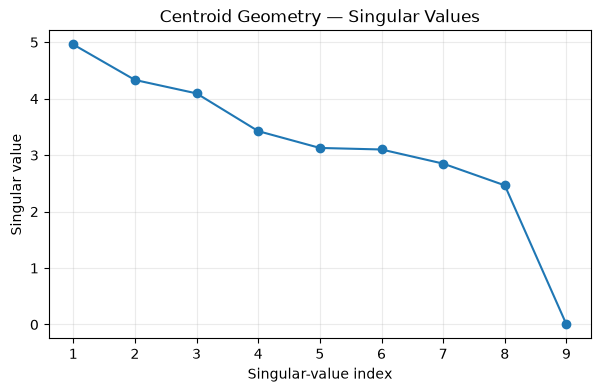

In [25]:

# Center the 9 population centroids
M_centered = M - M.mean(axis=0)

# Singular value decomposition
U, S, Vt = np.linalg.svd(
    M_centered,
    full_matrices=False
)

# Variance contributions
variance = S**2
explained = variance / variance.sum()

print("=== SINGULAR VALUES ===")
for i, (s, e) in enumerate(zip(S, explained), start=1):
    print(
        f"Dimension {i}: "
        f"singular value = {s:.6f}, "
        f"explained = {100*e:.2f}%"
    )

print("\n=== AFFINE RANK ===")
print("Rank:", np.linalg.matrix_rank(M_centered))

# Plot singular values
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, len(S) + 1),
    S,
    marker="o"
)

plt.xlabel("Singular-value index")
plt.ylabel("Singular value")
plt.title("Centroid Geometry — Singular Values")
plt.xticks(range(1, len(S) + 1))
plt.grid(alpha=0.25)

plt.show()


Bootstrap the centroid singular values

=== PCA ON ALL POPULATION VECTORS ===
Original shape: (494, 78)
Projected shape: (494, 3)

Explained variance:
PC1: 8.50%
PC2: 5.44%
PC3: 4.30%
Total explained: 18.25 %


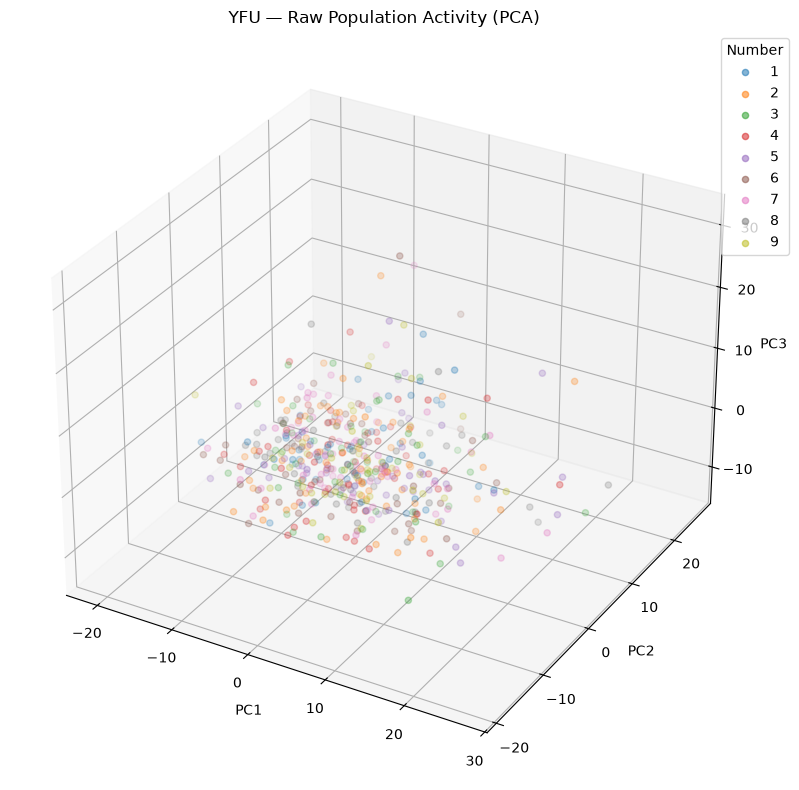

In [26]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# PCA on all 494 population vectors
pca = PCA(n_components=3)

X_pca = pca.fit_transform(X)

print("=== PCA ON ALL POPULATION VECTORS ===")
print("Original shape:", X.shape)
print("Projected shape:", X_pca.shape)

print("\nExplained variance:")
for i, value in enumerate(pca.explained_variance_ratio_):
    print(f"PC{i+1}: {100*value:.2f}%")

print(
    "Total explained:",
    round(100*pca.explained_variance_ratio_.sum(), 2),
    "%"
)

# 3D visualization
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

colors = plt.cm.tab10(np.arange(9))

for idx, k in enumerate(numbers):
    points = X_pca[y == k]

    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        color=colors[idx],
        label=str(k),
        s=20,
        alpha=0.55
    )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")

ax.set_title("YFU — Raw Population Activity (PCA)")
ax.legend(title="Number", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()


In [27]:

# Measure the spread of each number cloud in 78D

cloud_spreads = []

for idx, k in enumerate(numbers):
    cloud = X[y == k]
    centroid = M[idx]

    distances = np.linalg.norm(
        cloud - centroid,
        axis=1
    )

    rms_spread = np.sqrt(
        np.mean(distances**2)
    )

    cloud_spreads.append(rms_spread)

    print(
        f"Number {k}: "
        f"RMS spread = {rms_spread:.3f}"
    )

cloud_spreads = np.array(cloud_spreads)

print("\n=== SUMMARY ===")
print(
    "Mean within-cloud RMS spread:",
    round(cloud_spreads.mean(), 3)
)

print(
    "Mean between-centroid distance:",
    round(upper.mean(), 3)
)

print(
    "Separation / spread ratio:",
    round(upper.mean() / cloud_spreads.mean(), 3)
)


Number 1: RMS spread = 26.161
Number 2: RMS spread = 26.832
Number 3: RMS spread = 26.297
Number 4: RMS spread = 26.415
Number 5: RMS spread = 27.317
Number 6: RMS spread = 26.895
Number 7: RMS spread = 25.975
Number 8: RMS spread = 27.428
Number 9: RMS spread = 26.797

=== SUMMARY ===
Mean within-cloud RMS spread: 26.68
Mean between-centroid distance: 5.107
Separation / spread ratio: 0.191


=== LABEL-SHUFFLE NULL ===
Observed mean distance: 5.107
Null mean distance: 5.145
Null standard deviation: 0.204
Permutation p-value: 0.5784


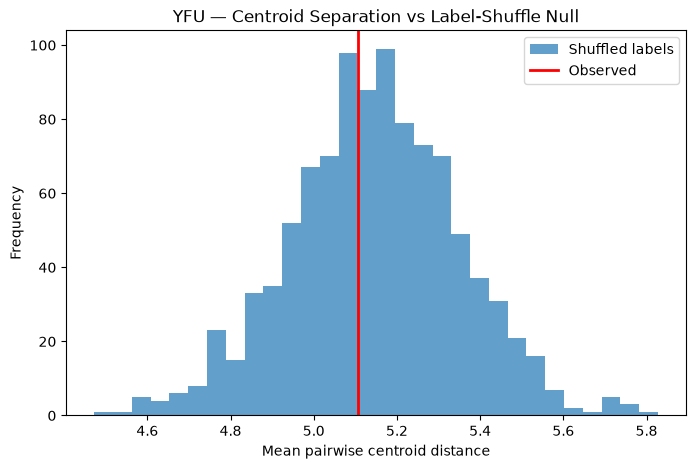

In [28]:

rng = np.random.default_rng(42)

B = 1000

null_mean_distances = np.zeros(B)

for b in range(B):

    # Randomly permute number labels
    y_shuffle = rng.permutation(y)

    # Compute shuffled centroids
    M_shuffle = np.vstack([
        X[y_shuffle == k].mean(axis=0)
        for k in numbers
    ])

    # Pairwise distances
    D_shuffle = squareform(
        pdist(M_shuffle, metric="euclidean")
    )

    null_mean_distances[b] = (
        D_shuffle[np.triu_indices(9, k=1)].mean()
    )

observed_mean_distance = upper.mean()

print("=== LABEL-SHUFFLE NULL ===")
print("Observed mean distance:", round(observed_mean_distance, 3))
print("Null mean distance:", round(null_mean_distances.mean(), 3))
print("Null standard deviation:", round(null_mean_distances.std(), 3))

p_value = (
    1 + np.sum(null_mean_distances >= observed_mean_distance)
) / (B + 1)

print("Permutation p-value:", round(p_value, 4))

plt.figure(figsize=(8, 5))

plt.hist(
    null_mean_distances,
    bins=30,
    alpha=0.7,
    label="Shuffled labels"
)

plt.axvline(
    observed_mean_distance,
    color="red",
    linewidth=2,
    label="Observed"
)

plt.xlabel("Mean pairwise centroid distance")
plt.ylabel("Frequency")
plt.title("YFU — Centroid Separation vs Label-Shuffle Null")
plt.legend()
plt.show()


In [29]:

from scipy.spatial.distance import pdist
from scipy.stats import pearsonr

rng = np.random.default_rng(42)

B = 1000
reliability = []

trial_ids = presentations["trial"].to_numpy()
unique_trials = np.unique(trial_ids)

for b in range(B):

    # Randomly split whole behavioral trials
    shuffled_trials = rng.permutation(unique_trials)
    midpoint = len(shuffled_trials) // 2

    trials_A = shuffled_trials[:midpoint]
    trials_B = shuffled_trials[midpoint:]

    mask_A = np.isin(trial_ids, trials_A)
    mask_B = np.isin(trial_ids, trials_B)

    # Skip splits missing any number class
    if any(
        np.sum(mask_A & (y == k)) == 0 or
        np.sum(mask_B & (y == k)) == 0
        for k in numbers
    ):
        continue

    # Centroids in each half
    M_A = np.vstack([
        X[mask_A & (y == k)].mean(axis=0)
        for k in numbers
    ])

    M_B = np.vstack([
        X[mask_B & (y == k)].mean(axis=0)
        for k in numbers
    ])

    # 36 pairwise distances in each half
    d_A = pdist(M_A, metric="euclidean")
    d_B = pdist(M_B, metric="euclidean")

    # Correlation of distance patterns
    r, _ = pearsonr(d_A, d_B)
    reliability.append(r)

reliability = np.array(reliability)

print("=== RANDOM SPLIT-HALF RELIABILITY ===")
print("Valid splits:", len(reliability))
print("Mean correlation:", round(reliability.mean(), 4))
print("Median correlation:", round(np.median(reliability), 4))
print("Standard deviation:", round(reliability.std(), 4))

print(
    "95% resampling interval:",
    np.round(np.percentile(reliability, [2.5, 97.5]), 4)
)

print(
    "Fraction positive:",
    round(np.mean(reliability > 0), 4)
)



=== RANDOM SPLIT-HALF RELIABILITY ===
Valid splits: 1000
Mean correlation: 0.0355
Median correlation: 0.0363
Standard deviation: 0.2099
95% resampling interval: [-0.3622  0.437 ]
Fraction positive: 0.57


Bootstrap centroid geometry

In [31]:

import numpy as np
from scipy.spatial.distance import pdist
from scipy.special import gammaln

rng = np.random.default_rng(42)

B = 1000
n_numbers = len(numbers)

bootstrap_singular_values = np.zeros((B, 8))
bootstrap_distances = np.zeros(B)
bootstrap_log_volumes = np.zeros(B)

clouds = {
    k: X[y == k]
    for k in numbers
}

for b in range(B):

    # Bootstrap centroid for each number
    M_boot = np.vstack([
        clouds[k][
            rng.integers(0, len(clouds[k]), size=len(clouds[k]))
        ].mean(axis=0)
        for k in numbers
    ])

    # Singular values of centered centroids
    M_centered_boot = M_boot - M_boot.mean(axis=0)
    s = np.linalg.svd(
        M_centered_boot,
        compute_uv=False
    )

    bootstrap_singular_values[b] = s[:8]

    # Mean pairwise centroid distance
    bootstrap_distances[b] = pdist(M_boot).mean()

    # Simplex volume using eight edge vectors
    E = M_boot[1:] - M_boot[0]

    edge_s = np.linalg.svd(E, compute_uv=False)

    # log(volume) = sum(log(singular values)) - log(8!)
    bootstrap_log_volumes[b] = (
        np.log(edge_s).sum() - gammaln(9)
    )

# Original geometry
M_original = np.vstack([
    clouds[k].mean(axis=0)
    for k in numbers
])

s_original = np.linalg.svd(
    M_original - M_original.mean(axis=0),
    compute_uv=False
)[:8]

E_original = M_original[1:] - M_original[0]

original_log_volume = (
    np.log(np.linalg.svd(E_original, compute_uv=False)).sum()
    - gammaln(9)
)

print("=== BOOTSTRAP CENTROID GEOMETRY ===")
print("Bootstrap repetitions:", B)

print("\nOriginal singular values:")
print(np.round(s_original, 3))

print("\nBootstrap mean singular values:")
print(np.round(bootstrap_singular_values.mean(axis=0), 3))

print("\nBootstrap singular-value 95% intervals:")
print(np.round(
    np.percentile(bootstrap_singular_values, [2.5, 97.5], axis=0).T,
    3
))

print("\nOriginal mean centroid distance:",
      round(pdist(M_original).mean(), 3))

print("Bootstrap mean centroid distance:",
      round(bootstrap_distances.mean(), 3))

print("Bootstrap distance 95% interval:",
      np.round(np.percentile(bootstrap_distances, [2.5, 97.5]), 3))

print("\nOriginal log simplex volume:",
      round(original_log_volume, 3))

print("Bootstrap mean log simplex volume:",
      round(bootstrap_log_volumes.mean(), 3))

print("Bootstrap log-volume 95% interval:",
      np.round(np.percentile(bootstrap_log_volumes, [2.5, 97.5]), 3))


=== BOOTSTRAP CENTROID GEOMETRY ===
Bootstrap repetitions: 1000

Original singular values:
[4.96  4.332 4.094 3.425 3.128 3.1   2.85  2.465]

Bootstrap mean singular values:
[7.026 6.189 5.581 5.061 4.629 4.218 3.825 3.349]

Bootstrap singular-value 95% intervals:
[[6.167 8.123]
 [5.53  6.963]
 [5.011 6.197]
 [4.566 5.562]
 [4.183 5.093]
 [3.786 4.65 ]
 [3.392 4.248]
 [2.851 3.816]]

Original mean centroid distance: 5.107
Bootstrap mean centroid distance: 7.198
Bootstrap distance 95% interval: [6.661 7.75 ]

Original log simplex volume: 0.423
Bootstrap mean log simplex volume: 3.115
Bootstrap log-volume 95% interval: [2.548 3.678]


In [32]:

import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist
from scipy.special import gammaln

rng = np.random.default_rng(42)
B = 1000

def simplex_features(P):
    """
    P: 9 x 78 matrix of points.
    Returns geometric features of their 8D simplex.
    """
    n = P.shape[0]
    d = n - 1

    # Centered geometry
    C = P - P.mean(axis=0)
    s = np.linalg.svd(C, compute_uv=False)[:d]

    # Pairwise Euclidean distances
    distances = pdist(P)

    mean_d = distances.mean()
    std_d = distances.std()

    # Eigenvalue weights from centered geometry
    eig = s**2
    weights = eig / eig.sum()

    # Effective dimension (participation ratio)
    effective_dim = eig.sum()**2 / np.sum(eig**2)

    # Eight-dimensional volume
    E = P[1:] - P[0]
    edge_s = np.linalg.svd(E, compute_uv=False)

    log_volume = np.log(edge_s).sum() - gammaln(n)

    # Regular 8-simplex with the same mean edge length
    # V_regular = sqrt(n) / (d! * sqrt(2**d)) * L**d
    log_regular_volume = (
        0.5 * np.log(n)
        - gammaln(n)
        - 0.5 * d * np.log(2)
        + d * np.log(mean_d)
    )

    return {
        "rank": np.linalg.matrix_rank(C),
        "mean_distance": mean_d,
        "min_distance": distances.min(),
        "max_distance": distances.max(),
        "distance_cv": std_d / mean_d,
        "effective_dimension": effective_dim,
        "condition_number": s[0] / s[-1],
        "log_volume": log_volume,
        "volume_ratio": np.exp(
            log_volume - log_regular_volume
        ),
        "sv1": s[0],
        "sv2": s[1],
        "sv3": s[2],
        "sv4": s[3],
        "sv5": s[4],
        "sv6": s[5],
        "sv7": s[6],
        "sv8": s[7],
    }


# Original centroid geometry
original = simplex_features(M_original)

# Bootstrap geometry
results = []
displacements = []

for b in range(B):

    M_boot = np.vstack([
        clouds[k][
            rng.integers(
                len(clouds[k]),
                size=len(clouds[k])
            )
        ].mean(axis=0)
        for k in numbers
    ])

    results.append(simplex_features(M_boot))

    displacements.append(
        np.linalg.norm(M_boot - M_original, axis=1).mean()
    )

boot_df = pd.DataFrame(results)

summary = pd.DataFrame({
    "Original": pd.Series(original),
    "Bootstrap mean": boot_df.mean(),
    "Bootstrap 2.5%": boot_df.quantile(0.025),
    "Bootstrap 97.5%": boot_df.quantile(0.975),
})

print("=== COMPLETE BOOTSTRAP SIMPLEX GEOMETRY ===")
print(summary.round(4).to_string())

print("\n=== CENTROID DISPLACEMENT ===")
print("Mean displacement:",
      round(np.mean(displacements), 4))
print("95% interval:",
      np.round(np.percentile(displacements, [2.5, 97.5]), 4))


=== COMPLETE BOOTSTRAP SIMPLEX GEOMETRY ===
                     Original  Bootstrap mean  Bootstrap 2.5%  Bootstrap 97.5%
rank                   8.0000          8.0000          8.0000           8.0000
mean_distance          5.1072          7.1984          6.6610           7.7497
min_distance           4.0716          5.6417          4.9849           6.2441
max_distance           6.0452          8.9944          7.9463          10.4456
distance_cv            0.1034          0.1117          0.0809           0.1561
effective_dimension    6.6710          6.5693          5.9127           7.1098
condition_number       2.0124          2.1093          1.7207           2.5858
log_volume             0.4231          3.1149          2.5478           3.6783
volume_ratio           0.7093          0.6788          0.5512           0.7931
sv1                    4.9599          7.0261          6.1674           8.1230
sv2                    4.3319          6.1894          5.5304           6.9633
sv3     

In [33]:

rng = np.random.default_rng(123)

B = 1000

noise_results = []

class_sizes = [
    np.sum(y == k)
    for k in numbers
]

for b in range(B):

    # All nine artificial clouds draw from the same pool
    M_noise = np.vstack([
        X[rng.integers(0, len(X), size=n)].mean(axis=0)
        for n in class_sizes
    ])

    noise_results.append(
        simplex_features(M_noise)
    )

noise_df = pd.DataFrame(noise_results)

comparison = pd.DataFrame({
    "Original": pd.Series(original),
    "Bootstrap mean": boot_df.mean(),
    "Noise-only mean": noise_df.mean(),
    "Noise 2.5%": noise_df.quantile(0.025),
    "Noise 97.5%": noise_df.quantile(0.975)
})

print("=== ORIGINAL VS BOOTSTRAP VS NOISE ===")
print(comparison.round(4).to_string())


=== ORIGINAL VS BOOTSTRAP VS NOISE ===
                     Original  Bootstrap mean  Noise-only mean  Noise 2.5%  Noise 97.5%
rank                   8.0000          8.0000           8.0000      8.0000       8.0000
mean_distance          5.1072          7.1984           5.1393      4.7484       5.5567
min_distance           4.0716          5.6417           3.9989      3.4869       4.4663
max_distance           6.0452          8.9944           6.4621      5.6290       7.5269
distance_cv            0.1034          0.1117           0.1128      0.0777       0.1544
effective_dimension    6.6710          6.5693           6.4512      5.6627       7.0449
condition_number       2.0124          2.1093           2.1976      1.7810       2.7350
log_volume             0.4231          3.1149           0.3751     -0.2245       0.9984
volume_ratio           0.7093          0.6788           0.6511      0.5207       0.7746
sv1                    4.9599          7.0261           5.1008      4.3837       

In [34]:

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

B = 1000

single_results = []

# Original number-specific clouds
clouds = {
    k: X[y == k]
    for k in numbers
}

for b in range(B):

    # Select exactly one vector from each number cloud
    Z = np.vstack([
        clouds[k][rng.integers(0, len(clouds[k]))]
        for k in numbers
    ])

    # Calculate all simplex geometric features
    single_results.append(simplex_features(Z))

single_df = pd.DataFrame(single_results)

single_summary = pd.DataFrame({
    "Single-vector mean": single_df.mean(),
    "Single-vector 2.5%": single_df.quantile(0.025),
    "Single-vector 97.5%": single_df.quantile(0.975)
})

print("=== SINGLE-VECTOR SIMPLEX GEOMETRY ===")
print(single_summary.round(4).to_string())


=== SINGLE-VECTOR SIMPLEX GEOMETRY ===
                     Single-vector mean  Single-vector 2.5%  Single-vector 97.5%
rank                             8.0000              8.0000               8.0000
mean_distance                   37.8305             34.4686              41.9188
min_distance                    29.6015             25.7274              33.1817
max_distance                    47.4412             40.6937              57.7495
distance_cv                      0.1132              0.0759               0.1768
effective_dimension              6.5007              5.5941               7.1329
condition_number                 2.1387              1.7281               2.7196
log_volume                      16.3694             15.7084              17.0628
volume_ratio                     0.6694              0.5104               0.7968
sv1                             37.4196             31.4950              45.7849
sv2                             32.4125             28.4887           

In [35]:

rng = np.random.default_rng(123)

B = 1000
single_noise_results = []

for b in range(B):

    # Select nine vectors from the common neural pool
    indices = rng.integers(
        0, len(X), size=9
    )

    Z_noise = X[indices]

    # Calculate the same simplex features
    single_noise_results.append(
        simplex_features(Z_noise)
    )

single_noise_df = pd.DataFrame(single_noise_results)

comparison = pd.DataFrame({
    "Labeled single-vector mean": single_df.mean(),
    "Noise-only mean": single_noise_df.mean(),
    "Noise 2.5%": single_noise_df.quantile(0.025),
    "Noise 97.5%": single_noise_df.quantile(0.975)
})

print("=== SINGLE-VECTOR VS POOLED NOISE ===")
print(comparison.round(4).to_string())


C:\Users\shafi\AppData\Local\Temp\ipykernel_20084\2779143461.py:38: RuntimeWarning: divide by zero encountered in log
  log_volume = np.log(edge_s).sum() - gammaln(n)


=== SINGLE-VECTOR VS POOLED NOISE ===
                     Labeled single-vector mean  Noise-only mean  Noise 2.5%   Noise 97.5%
rank                                     8.0000     7.926000e+00      7.0000  8.000000e+00
mean_distance                           37.8305     3.769420e+01     34.0869  4.153410e+01
min_distance                            29.6015     2.738500e+01      0.0000  3.322840e+01
max_distance                            47.4412     4.745490e+01     40.6765  5.644950e+01
distance_cv                              0.1132     1.202000e-01      0.0746  2.064000e-01
effective_dimension                      6.5007     6.419700e+00      5.3902  7.102600e+00
condition_number                         2.1387     2.403226e+14      1.7527  3.129955e+15
log_volume                              16.3694             -inf    -20.4155  1.702780e+01
volume_ratio                             0.6694     6.190000e-01      0.0000  7.948000e-01
sv1                                     37.4196     

In [36]:

rng = np.random.default_rng(123)

B = 1000
single_noise_results = []

for b in range(B):

    # Select 9 distinct vectors from all 494 presentations
    indices = rng.choice(
        len(X),
        size=9,
        replace=False
    )

    Z_noise = X[indices]

    single_noise_results.append(
        simplex_features(Z_noise)
    )

single_noise_df = pd.DataFrame(single_noise_results)

comparison = pd.DataFrame({
    "Labeled single-vector mean": single_df.mean(),
    "Noise-only mean": single_noise_df.mean(),
    "Noise 2.5%": single_noise_df.quantile(0.025),
    "Noise 97.5%": single_noise_df.quantile(0.975)
})

print("=== CORRECTED SINGLE-VECTOR VS POOLED NOISE ===")
print(comparison.round(4).to_string())


=== CORRECTED SINGLE-VECTOR VS POOLED NOISE ===
                     Labeled single-vector mean  Noise-only mean  Noise 2.5%  Noise 97.5%
rank                                     8.0000           8.0000      8.0000       8.0000
mean_distance                           37.8305          37.7003     34.4489      41.5175
min_distance                            29.6015          29.4716     25.3372      33.1964
max_distance                            47.4412          47.3836     40.8711      57.3276
distance_cv                              0.1132           0.1138      0.0747       0.1751
effective_dimension                      6.5007           6.4967      5.5984       7.1412
condition_number                         2.1387           2.1436      1.7297       2.7313
log_volume                              16.3694          16.3417     15.6793      17.0698
volume_ratio                             0.6694           0.6689      0.5177       0.7979
sv1                                     37.4196     

In [37]:

import pandas as pd

# Combine all five methods into one table
comparison_all = pd.DataFrame({
    "Original centroids": pd.Series(original),
    "Bootstrap centroids": boot_df.mean(),
    "Pooled noise centroids": noise_df.mean(),
    "Labeled single vectors": single_df.mean(),
    "Pooled single vectors": single_noise_df.mean()
})

# Arrange the geometric features
feature_order = [
    "rank",
    "mean_distance",
    "min_distance",
    "max_distance",
    "distance_cv",
    "effective_dimension",
    "condition_number",
    "log_volume",
    "volume_ratio",
    "sv1",
    "sv2",
    "sv3",
    "sv4",
    "sv5",
    "sv6",
    "sv7",
    "sv8"
]

comparison_all = comparison_all.loc[feature_order]

# Rename rows for readability
comparison_all.index = [
    "Affine rank",
    "Mean pairwise distance",
    "Minimum pairwise distance",
    "Maximum pairwise distance",
    "Distance CV",
    "Effective dimension",
    "Condition number",
    "Log simplex volume",
    "Relative simplex volume",
    "Singular value 1",
    "Singular value 2",
    "Singular value 3",
    "Singular value 4",
    "Singular value 5",
    "Singular value 6",
    "Singular value 7",
    "Singular value 8"
]

print("=== YFU: COMPARISON OF ALL FIVE GEOMETRY METHODS ===")
display(comparison_all.round(4))

# Save as CSV for GitHub / further analysis
output_path = ROOT / "tables1" / "YFU_all_simplex_geometry_comparison.csv"

output_path.parent.mkdir(parents=True, exist_ok=True)

comparison_all.to_csv(output_path)

print(f"\nSaved to: {output_path}")


=== YFU: COMPARISON OF ALL FIVE GEOMETRY METHODS ===


,Original centroids,Bootstrap centroids,Pooled noise centroids,Labeled single vectors,Pooled single vectors
Affine rank,8.0000,8.0000,8.0000,8.0000,8.0000
Mean pairwise distance,5.1072,7.1984,5.1393,37.8305,37.7003
Minimum pairwise distance,4.0716,5.6417,3.9989,29.6015,29.4716
Maximum pairwise distance,6.0452,8.9944,6.4621,47.4412,47.3836
Distance CV,0.1034,0.1117,0.1128,0.1132,0.1138
Effective dimension,6.6710,6.5693,6.4512,6.5007,6.4967
Condition number,2.0124,2.1093,2.1976,2.1387,2.1436
Log simplex volume,0.4231,3.1149,0.3751,16.3694,16.3417
Relative simplex volume,0.7093,0.6788,0.6511,0.6694,0.6689
Singular value 1,4.9599,7.0261,5.1008,37.4196,37.3527



Saved to: c:\Users\shafi\number-simplex-reproduction\tables1\YFU_all_simplex_geometry_comparison.csv


In [38]:

import numpy as np
import pandas as pd

# spikes_csc: sparse matrix, shape (78, total_time_ms)
# presentations: same 494 presentations as before

BIN_MS = 100
N_BINS = 9
WINDOW_START_MS = 50

n_presentations = len(presentations)
n_neurons = spikes_csc.shape[0]

# Shape: presentations x neurons x time bins
temporal_counts = np.zeros(
    (n_presentations, n_neurons, N_BINS),
    dtype=np.int32
)

for i, onset in enumerate(presentations["onset"]):

    for b in range(N_BINS):

        start = int(np.ceil(
            onset + WINDOW_START_MS + b * BIN_MS
        ))

        end = int(np.ceil(
            onset + WINDOW_START_MS + (b + 1) * BIN_MS
        ))

        temporal_counts[i, :, b] = np.asarray(
            spikes_csc[:, start:end].sum(axis=1)
        ).ravel()

# Convert spike counts to firing rates (Hz)
temporal_rates = temporal_counts / (BIN_MS / 1000)

# Flatten to 494 x 702
X_temporal = temporal_rates.reshape(
    n_presentations,
    n_neurons * N_BINS
)

# Descriptive feature names
columns = [
    f"neuron_{j:02d}_bin_{b+1:02d}"
    for j in range(n_neurons)
    for b in range(N_BINS)
]

temporal_df = pd.DataFrame(
    X_temporal,
    columns=columns
)

output_path = ROOT / "tables1" / "YFU_arithmetic_temporal_rates_100ms.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

temporal_df.to_csv(output_path, index=False)

print("Temporal count shape:", temporal_counts.shape)
print("Temporal rate shape:", X_temporal.shape)
print("Saved:", output_path)

# Validation: temporal counts must recover original totals
recovered_counts = temporal_counts.sum(axis=2)

print(
    "Original 900 ms counts recovered:",
    np.array_equal(recovered_counts, X)
)


NameError: name 'spikes_csc' is not defined

In [39]:

import numpy as np
import pandas as pd

# Load temporal firing rates (100 ms bins)
temporal_file = ROOT / "tables1" / "YFU_arithmetic_temporal_rates_100ms.csv"

X_temporal = pd.read_csv(temporal_file).to_numpy(dtype=float)

# Use the same number labels as our original analysis
y_temporal = presentations["number"].to_numpy()

numbers_temporal = np.arange(1, 10)

# Separate temporal population responses by number
temporal_clouds = {
    k: X_temporal[y_temporal == k]
    for k in numbers_temporal
}

print("=== TEMPORAL POPULATION DATA ===")
print("Temporal matrix:", X_temporal.shape)
print("Number labels:", y_temporal.shape)
print("Neurons:", 78)
print("Time bins:", 9)
print("Features:", X_temporal.shape[1])

print("\nPresentations per number:")
for k in numbers_temporal:
    print(f"Number {k}: {len(temporal_clouds[k])}")

print("\nMean firing rate (Hz):", X_temporal.mean())


=== TEMPORAL POPULATION DATA ===
Temporal matrix: (494, 702)
Number labels: (494,)
Neurons: 78
Time bins: 9
Features: 702

Presentations per number:
Number 1: 53
Number 2: 67
Number 3: 52
Number 4: 62
Number 5: 51
Number 6: 48
Number 7: 65
Number 8: 49
Number 9: 47

Mean firing rate (Hz): 8.718727291601786


In [40]:

# ============================================
# STEP 34: ORIGINAL TEMPORAL CENTROID GEOMETRY
# ============================================

# Calculate the mean temporal response for each number
M_temporal = np.vstack([
    temporal_clouds[k].mean(axis=0)
    for k in numbers_temporal
])

# Reuse our existing simplex geometry function
temporal_original = simplex_features(M_temporal)

print("=== ORIGINAL TEMPORAL CENTROID GEOMETRY ===")
print("Centroid matrix shape:", M_temporal.shape)

print("\nGeometric features:")
for feature, value in temporal_original.items():
    print(f"{feature:25s}: {value:.4f}")

# Compare scale-independent geometry with
# the original 900 ms total-count representation
scale_independent = [
    "rank",
    "distance_cv",
    "effective_dimension",
    "condition_number",
    "volume_ratio"
]

comparison = pd.DataFrame({
    "900 ms total counts": pd.Series(original),
    "9 x 100 ms temporal rates": pd.Series(temporal_original)
})

print("\n=== SCALE-INDEPENDENT COMPARISON ===")
display(comparison.loc[scale_independent].round(4))


=== ORIGINAL TEMPORAL CENTROID GEOMETRY ===
Centroid matrix shape: (9, 702)

Geometric features:
rank                     : 8.0000
mean_distance            : 46.7111
min_distance             : 40.5437
max_distance             : 52.1387
distance_cv              : 0.0642
effective_dimension      : 7.6605
condition_number         : 1.3860
log_volume               : 18.3970
volume_ratio             : 0.9265
sv1                      : 38.0480
sv2                      : 36.2129
sv3                      : 35.4942
sv4                      : 34.2575
sv5                      : 32.9020
sv6                      : 29.7931
sv7                      : 29.1129
sv8                      : 27.4512

=== SCALE-INDEPENDENT COMPARISON ===


,900 ms total counts,9 x 100 ms temporal rates
rank,8.0000,8.0000
distance_cv,0.1034,0.0642
effective_dimension,6.6710,7.6605
condition_number,2.0124,1.3860
volume_ratio,0.7093,0.9265


In [41]:

# ============================================
# STEP 35: TEMPORAL CENTROID BOOTSTRAPPING
# ============================================

rng = np.random.default_rng(123)
B = 1000

temporal_boot_results = []

for b in range(B):

    centroids = []

    for k in numbers_temporal:

        cloud = temporal_clouds[k]

        indices = rng.integers(
            0, len(cloud), size=len(cloud)
        )

        centroid = cloud[indices].mean(axis=0)

        centroids.append(centroid)

    M_boot = np.vstack(centroids)

    temporal_boot_results.append(
        simplex_features(M_boot)
    )

temporal_boot_df = pd.DataFrame(temporal_boot_results)

comparison = pd.DataFrame({
    "Original temporal": pd.Series(temporal_original),
    "Bootstrap mean": temporal_boot_df.mean(),
    "Bootstrap 2.5%": temporal_boot_df.quantile(0.025),
    "Bootstrap 97.5%": temporal_boot_df.quantile(0.975)
})

print("=== TEMPORAL CENTROID BOOTSTRAP ===")
display(comparison.round(4))


=== TEMPORAL CENTROID BOOTSTRAP ===


,Original temporal,Bootstrap mean,Bootstrap 2.5%,Bootstrap 97.5%
rank,8.0000,8.0000,8.0000,8.0000
mean_distance,46.7111,66.4176,63.9427,69.0895
min_distance,40.5437,57.5550,53.8115,61.2820
max_distance,52.1387,75.0661,70.2204,81.1050
distance_cv,0.0642,0.0647,0.0427,0.0869
effective_dimension,7.6605,7.6466,7.4510,7.8117
condition_number,1.3860,1.3992,1.2749,1.5412
log_volume,18.3970,21.2105,20.9051,21.5185
volume_ratio,0.9265,0.9260,0.8868,0.9589
sv1,38.0480,54.7445,51.2216,59.0375


In [42]:

# ==============================================
# STEP 36: TEMPORAL POOLED CENTROID NOISE CONTROL
# ==============================================

rng = np.random.default_rng(123)
B = 1000

temporal_noise_results = []

# Preserve the original number-specific sample sizes
class_sizes = [
    len(temporal_clouds[k])
    for k in numbers_temporal
]

for b in range(B):

    noise_centroids = []

    for n_k in class_sizes:

        # Sample from all presentations, ignoring labels
        indices = rng.integers(
            0,
            len(X_temporal),
            size=n_k
        )

        centroid = X_temporal[indices].mean(axis=0)

        noise_centroids.append(centroid)

    M_noise = np.vstack(noise_centroids)

    temporal_noise_results.append(
        simplex_features(M_noise)
    )

temporal_noise_df = pd.DataFrame(temporal_noise_results)

comparison = pd.DataFrame({
    "Original temporal": pd.Series(temporal_original),
    "Bootstrap mean": temporal_boot_df.mean(),
    "Pooled noise mean": temporal_noise_df.mean(),
    "Noise 2.5%": temporal_noise_df.quantile(0.025),
    "Noise 97.5%": temporal_noise_df.quantile(0.975)
})

print("=== TEMPORAL CENTROID VS POOLED NOISE ===")
display(comparison.round(4))


=== TEMPORAL CENTROID VS POOLED NOISE ===


,Original temporal,Bootstrap mean,Pooled noise mean,Noise 2.5%,Noise 97.5%
rank,8.0000,8.0000,8.0000,8.0000,8.0000
mean_distance,46.7111,66.4176,47.6022,46.0426,49.1936
min_distance,40.5437,57.5550,41.6490,38.9233,44.2079
max_distance,52.1387,75.0661,53.4979,50.4426,57.0021
distance_cv,0.0642,0.0647,0.0594,0.0406,0.0788
effective_dimension,7.6605,7.6466,7.6072,7.4199,7.7623
condition_number,1.3860,1.3992,1.4296,1.3130,1.5655
log_volume,18.3970,21.2105,18.5330,18.2715,18.7950
volume_ratio,0.9265,0.9260,0.9138,0.8755,0.9470
sv1,38.0480,54.7445,39.6373,37.3867,42.2721


In [43]:

# ==============================================
# STEP 37: LABELED SINGLE-VECTOR TEMPORAL GEOMETRY
# ==============================================

rng = np.random.default_rng(123)
B = 1000

temporal_single_results = []

for b in range(B):

    selected_vectors = []

    for k in numbers_temporal:

        cloud = temporal_clouds[k]

        index = rng.integers(0, len(cloud))

        selected_vectors.append(cloud[index])

    Z_temporal = np.vstack(selected_vectors)

    temporal_single_results.append(
        simplex_features(Z_temporal)
    )

temporal_single_df = pd.DataFrame(temporal_single_results)

comparison = pd.DataFrame({
    "Original temporal": pd.Series(temporal_original),
    "Labeled single-vector mean": temporal_single_df.mean(),
    "Single-vector 2.5%": temporal_single_df.quantile(0.025),
    "Single-vector 97.5%": temporal_single_df.quantile(0.975)
})

print("=== LABELED SINGLE-VECTOR TEMPORAL GEOMETRY ===")
display(comparison.round(4))


=== LABELED SINGLE-VECTOR TEMPORAL GEOMETRY ===


,Original temporal,Labeled single-vector mean,Single-vector 2.5%,Single-vector 97.5%
rank,8.0000,8.0000,8.0000,8.0000
mean_distance,46.7111,350.5535,339.3574,364.1119
min_distance,40.5437,322.2964,307.0831,336.3072
max_distance,52.1387,380.3712,360.9640,401.8768
distance_cv,0.0642,0.0398,0.0271,0.0553
effective_dimension,7.6605,7.8016,7.6915,7.8860
condition_number,1.3860,1.2827,1.2043,1.3818
log_volume,18.3970,34.5521,34.2972,34.8485
volume_ratio,0.9265,0.9569,0.9340,0.9742
sv1,38.0480,279.6882,263.3928,296.5153


In [44]:

# ==============================================
# STEP 38: POOLED SINGLE-VECTOR TEMPORAL CONTROL
# ==============================================

rng = np.random.default_rng(123)
B = 1000

temporal_single_noise_results = []

for b in range(B):

    # Select nine distinct temporal population vectors
    # without using number labels
    indices = rng.choice(
        len(X_temporal),
        size=9,
        replace=False
    )

    Z_noise = X_temporal[indices]

    temporal_single_noise_results.append(
        simplex_features(Z_noise)
    )

temporal_single_noise_df = pd.DataFrame(
    temporal_single_noise_results
)

comparison = pd.DataFrame({
    "Labeled single-vector mean": temporal_single_df.mean(),
    "Pooled single-vector mean": temporal_single_noise_df.mean(),
    "Noise 2.5%": temporal_single_noise_df.quantile(0.025),
    "Noise 97.5%": temporal_single_noise_df.quantile(0.975)
})

print("=== TEMPORAL SINGLE-VECTOR VS POOLED CONTROL ===")
display(comparison.round(4))


=== TEMPORAL SINGLE-VECTOR VS POOLED CONTROL ===


,Labeled single-vector mean,Pooled single-vector mean,Noise 2.5%,Noise 97.5%
rank,8.0000,8.0000,8.0000,8.0000
mean_distance,350.5535,350.2518,338.7507,362.5352
min_distance,322.2964,322.1534,306.9161,336.3072
max_distance,380.3712,380.2259,360.9709,401.6279
distance_cv,0.0398,0.0398,0.0269,0.0556
effective_dimension,7.8016,7.8003,7.6890,7.8879
condition_number,1.2827,1.2824,1.1993,1.3804
log_volume,34.5521,34.5451,34.2768,34.8211
volume_ratio,0.9569,0.9567,0.9355,0.9751
sv1,279.6882,279.6289,264.4340,295.8354


In [45]:

# ==============================================
# STEP 39: COMPLETE GEOMETRY COMPARISON
# ==============================================

import pandas as pd

all_geometry = pd.DataFrame({
    "Count | Original": pd.Series(original),
    "Count | Bootstrap": boot_df.mean(),
    "Count | Pooled centroid": noise_df.mean(),
    "Count | Labeled single": single_df.mean(),
    "Count | Pooled single": single_noise_df.mean(),

    "Temporal | Original": pd.Series(temporal_original),
    "Temporal | Bootstrap": temporal_boot_df.mean(),
    "Temporal | Pooled centroid": temporal_noise_df.mean(),
    "Temporal | Labeled single": temporal_single_df.mean(),
    "Temporal | Pooled single": temporal_single_noise_df.mean()
})

feature_order = [
    "rank",
    "mean_distance",
    "min_distance",
    "max_distance",
    "distance_cv",
    "effective_dimension",
    "condition_number",
    "log_volume",
    "volume_ratio",
    "sv1", "sv2", "sv3", "sv4",
    "sv5", "sv6", "sv7", "sv8"
]

all_geometry = all_geometry.loc[feature_order]

print("=== ALL TEN POPULATION GEOMETRY ANALYSES ===")
display(all_geometry.round(4))

# Separate scale-independent shape comparison
shape_features = [
    "rank",
    "distance_cv",
    "effective_dimension",
    "condition_number",
    "volume_ratio"
]

print("\n=== SCALE-INDEPENDENT SHAPE COMPARISON ===")
display(all_geometry.loc[shape_features].round(4))

# Save results
output_file = (
    ROOT / "tables1" /
    "YFU_count_vs_temporal_geometry_comparison.csv"
)

output_file.parent.mkdir(parents=True, exist_ok=True)
all_geometry.to_csv(output_file)

print("\nSaved:", output_file)


=== ALL TEN POPULATION GEOMETRY ANALYSES ===


,Count | Original,Count | Bootstrap,Count | Pooled centroid,Count | Labeled single,Count | Pooled single,Temporal | Original,Temporal | Bootstrap,Temporal | Pooled centroid,Temporal | Labeled single,Temporal | Pooled single
rank,8.0000,8.0000,8.0000,8.0000,8.0000,8.0000,8.0000,8.0000,8.0000,8.0000
mean_distance,5.1072,7.1984,5.1393,37.8305,37.7003,46.7111,66.4176,47.6022,350.5535,350.2518
min_distance,4.0716,5.6417,3.9989,29.6015,29.4716,40.5437,57.5550,41.6490,322.2964,322.1534
max_distance,6.0452,8.9944,6.4621,47.4412,47.3836,52.1387,75.0661,53.4979,380.3712,380.2259
distance_cv,0.1034,0.1117,0.1128,0.1132,0.1138,0.0642,0.0647,0.0594,0.0398,0.0398
effective_dimension,6.6710,6.5693,6.4512,6.5007,6.4967,7.6605,7.6466,7.6072,7.8016,7.8003
condition_number,2.0124,2.1093,2.1976,2.1387,2.1436,1.3860,1.3992,1.4296,1.2827,1.2824
log_volume,0.4231,3.1149,0.3751,16.3694,16.3417,18.3970,21.2105,18.5330,34.5521,34.5451
volume_ratio,0.7093,0.6788,0.6511,0.6694,0.6689,0.9265,0.9260,0.9138,0.9569,0.9567
sv1,4.9599,7.0261,5.1008,37.4196,37.3527,38.0480,54.7445,39.6373,279.6882,279.6289



=== SCALE-INDEPENDENT SHAPE COMPARISON ===


,Count | Original,Count | Bootstrap,Count | Pooled centroid,Count | Labeled single,Count | Pooled single,Temporal | Original,Temporal | Bootstrap,Temporal | Pooled centroid,Temporal | Labeled single,Temporal | Pooled single
rank,8.0000,8.0000,8.0000,8.0000,8.0000,8.0000,8.0000,8.0000,8.0000,8.0000
distance_cv,0.1034,0.1117,0.1128,0.1132,0.1138,0.0642,0.0647,0.0594,0.0398,0.0398
effective_dimension,6.6710,6.5693,6.4512,6.5007,6.4967,7.6605,7.6466,7.6072,7.8016,7.8003
condition_number,2.0124,2.1093,2.1976,2.1387,2.1436,1.3860,1.3992,1.4296,1.2827,1.2824
volume_ratio,0.7093,0.6788,0.6511,0.6694,0.6689,0.9265,0.9260,0.9138,0.9569,0.9567



Saved: c:\Users\shafi\number-simplex-reproduction\tables1\YFU_count_vs_temporal_geometry_comparison.csv


Valid splits: 1000
Distance matrix shape: (9, 9)
Mean CV squared distance: -97.99481952712337
Minimum: -430.8382718350013
Maximum: 311.2099889712726
Positive pairs: 8 / 36


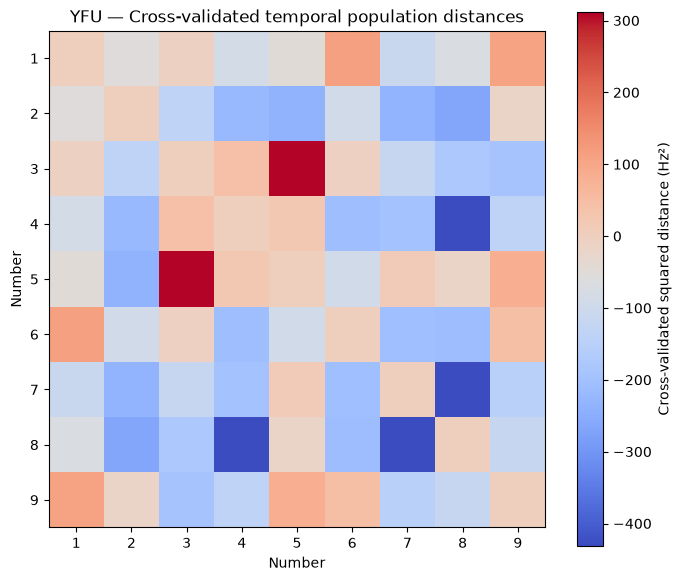

In [46]:

# ==============================================
# STEP 40: CROSS-VALIDATED TEMPORAL DISTANCES
# ==============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(123)
B = 1000

trial_ids = presentations["trial"].to_numpy()
unique_trials = np.unique(trial_ids)

cv_distances = []

for b in range(B):

    shuffled_trials = rng.permutation(unique_trials)
    midpoint = len(shuffled_trials) // 2

    trials_A = shuffled_trials[:midpoint]
    trials_B = shuffled_trials[midpoint:]

    mask_A = np.isin(trial_ids, trials_A)
    mask_B = np.isin(trial_ids, trials_B)

    # Ensure every number appears in both halves
    if any(
        not np.any(mask_A & (y_temporal == k))
        or not np.any(mask_B & (y_temporal == k))
        for k in numbers_temporal
    ):
        continue

    M_A = np.vstack([
        X_temporal[mask_A & (y_temporal == k)].mean(axis=0)
        for k in numbers_temporal
    ])

    M_B = np.vstack([
        X_temporal[mask_B & (y_temporal == k)].mean(axis=0)
        for k in numbers_temporal
    ])

    D = np.zeros((9, 9))

    for i in range(9):
        for j in range(i + 1, 9):

            diff_A = M_A[i] - M_A[j]
            diff_B = M_B[i] - M_B[j]

            value = np.dot(diff_A, diff_B)

            D[i, j] = value
            D[j, i] = value

    cv_distances.append(D)

cv_distances = np.asarray(cv_distances)
D_mean = cv_distances.mean(axis=0)

print("Valid splits:", len(cv_distances))
print("Distance matrix shape:", D_mean.shape)

upper = np.triu_indices(9, k=1)
pair_values = D_mean[upper]

print("Mean CV squared distance:", pair_values.mean())
print("Minimum:", pair_values.min())
print("Maximum:", pair_values.max())
print("Positive pairs:", np.sum(pair_values > 0), "/ 36")

plt.figure(figsize=(7, 6))
plt.imshow(D_mean, cmap="coolwarm")
plt.colorbar(label="Cross-validated squared distance (Hz²)")
plt.xticks(range(9), numbers_temporal)
plt.yticks(range(9), numbers_temporal)
plt.xlabel("Number")
plt.ylabel("Number")
plt.title("YFU — Cross-validated temporal population distances")
plt.tight_layout()
plt.show()


In [47]:

# ==============================================
# STEP 41: CHECK TRIAL-SPLIT COMPOSITION
# ==============================================

rng = np.random.default_rng(123)

shuffled_trials = rng.permutation(unique_trials)
midpoint = len(shuffled_trials) // 2

trials_A = shuffled_trials[:midpoint]
trials_B = shuffled_trials[midpoint:]

split_labels = np.where(
    np.isin(trial_ids, trials_A),
    "A",
    "B"
)

split_check = presentations[
    ["number", "operand_position"]
].copy()

split_check["split"] = split_labels

print("=== NUMBER COUNTS PER SPLIT ===")
display(pd.crosstab(
    split_check["number"],
    split_check["split"]
))

print("\n=== NUMBER × OPERAND POSITION × SPLIT ===")
display(pd.crosstab(
    [split_check["number"], split_check["operand_position"]],
    split_check["split"]
))


=== NUMBER COUNTS PER SPLIT ===


split,A,B
number,,
1,20,33
2,40,27
3,20,32
4,29,33
5,24,27
6,25,23
7,36,29
8,28,21
9,24,23



=== NUMBER × OPERAND POSITION × SPLIT ===


split                     A   B
number operand_position        
1      1                 11  17
       2                  9  16
2      1                 19  11
       2                 21  16
3      1                 13  14
       2                  7  18
4      1                  7  20
       2                 22  13
5      1                 11  12
       2                 13  15
6      1                 13  13
       2                 12  10
7      1                 23  14
       2                 13  15
8      1                 13  11
       2                 15  10
9      1                 14   8
       2                 10  15

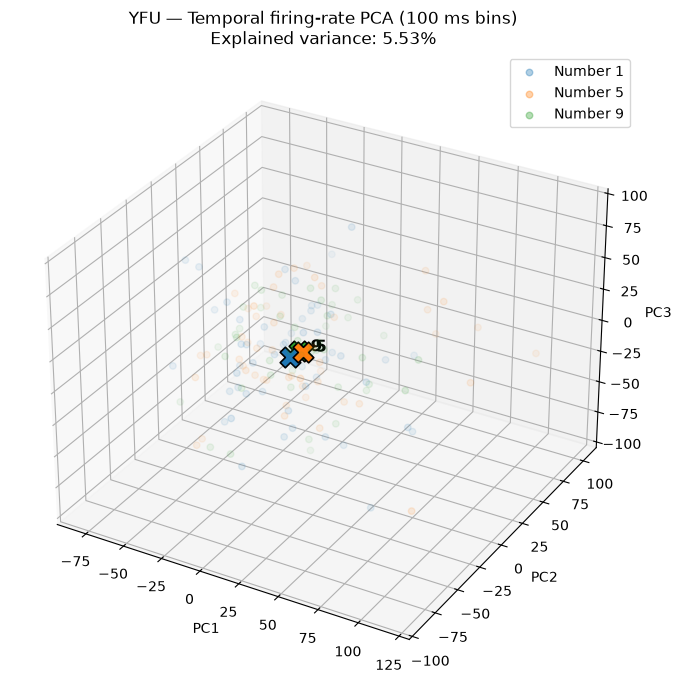

Selected numbers: [1, 5, 9]
Number of presentations: 151
Explained variance ratios: [0.0201 0.0185 0.0167]


In [48]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Choose any two or three numbers
selected_numbers = [1, 5, 9]

# Select corresponding temporal population responses
mask = np.isin(y_temporal, selected_numbers)

X_selected = X_temporal[mask]
y_selected = y_temporal[mask]

# Unsupervised PCA on selected data
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_selected)

# Calculate centroids in PCA space
centroids_pca = {
    k: X_pca[y_selected == k].mean(axis=0)
    for k in selected_numbers
}

# 3D visualization
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

colors = ["tab:blue", "tab:orange", "tab:green"]

for k, color in zip(selected_numbers, colors):

    points = X_pca[y_selected == k]

    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        color=color,
        alpha=0.35,
        s=22,
        label=f"Number {k}"
    )

    centroid = centroids_pca[k]

    ax.scatter(
        *centroid,
        color=color,
        marker="X",
        s=220,
        edgecolor="black",
        linewidth=1.2
    )

    ax.text(
        *centroid,
        f"  {k}",
        fontsize=12,
        weight="bold"
    )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")

ax.set_title(
    "YFU — Temporal firing-rate PCA (100 ms bins)\n"
    f"Explained variance: {pca.explained_variance_ratio_.sum()*100:.2f}%"
)

ax.legend()
plt.tight_layout()
plt.show()

print("Selected numbers:", selected_numbers)
print("Number of presentations:", len(X_selected))
print(
    "Explained variance ratios:",
    np.round(pca.explained_variance_ratio_, 4)
)


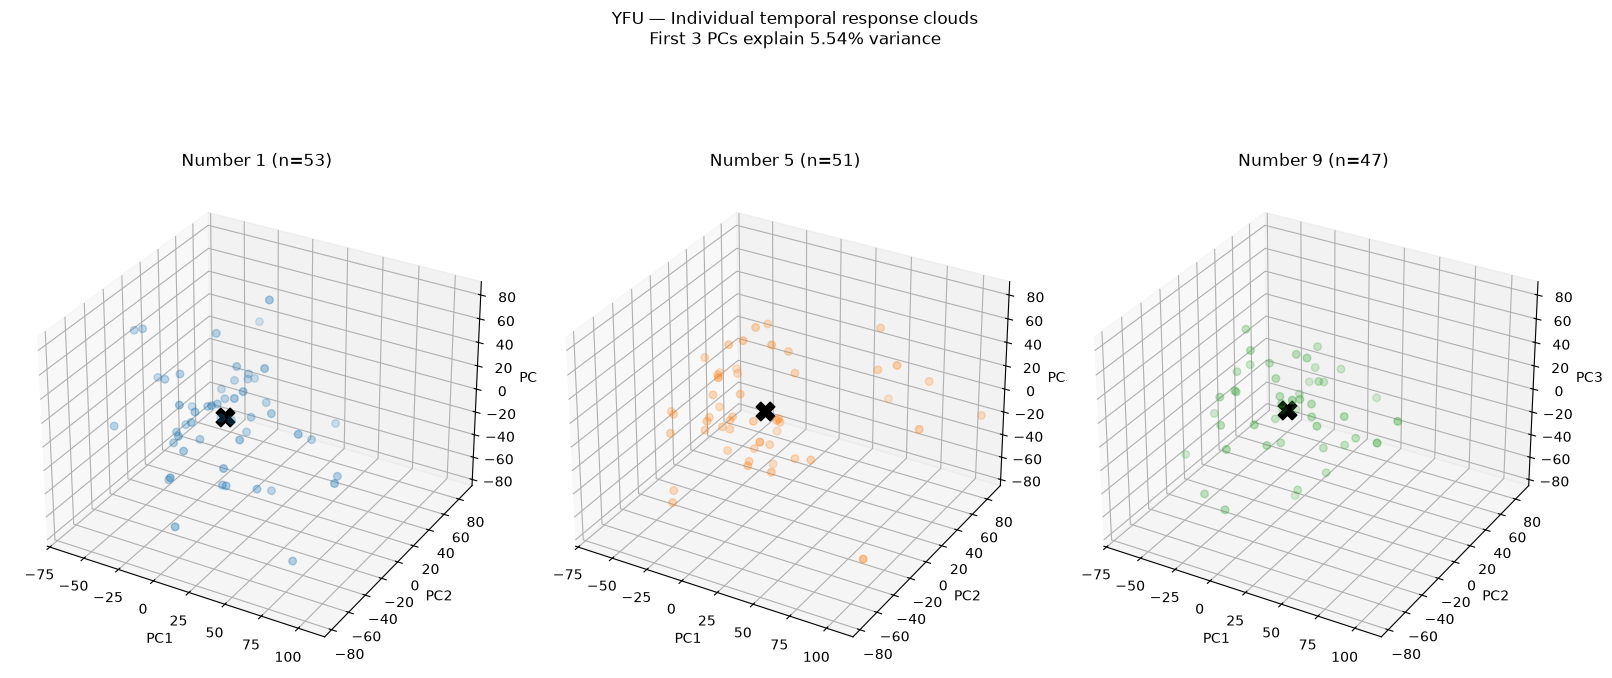

In [49]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

selected_numbers = [1, 5, 9]

mask = np.isin(y_temporal, selected_numbers)
X_selected = X_temporal[mask]
y_selected = y_temporal[mask]

pca = PCA(n_components=3)
Z = pca.fit_transform(X_selected)

colors = ["tab:blue", "tab:orange", "tab:green"]

fig = plt.figure(figsize=(16, 8))

# Common axis limits for fair comparison
limits = [
    (Z[:, i].min(), Z[:, i].max())
    for i in range(3)
]

for idx, (k, color) in enumerate(zip(selected_numbers, colors)):

    ax = fig.add_subplot(1, 3, idx + 1, projection="3d")

    points = Z[y_selected == k]
    centroid = points.mean(axis=0)

    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        color=color,
        alpha=0.65,
        s=30
    )

    ax.scatter(
        *centroid,
        color="black",
        marker="X",
        s=180
    )

    ax.set_xlim(*limits[0])
    ax.set_ylim(*limits[1])
    ax.set_zlim(*limits[2])

    ax.set_title(f"Number {k} (n={len(points)})")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")

plt.suptitle(
    "YFU — Individual temporal response clouds\n"
    f"First 3 PCs explain {pca.explained_variance_ratio_.sum()*100:.2f}% variance"
)

plt.tight_layout()
plt.show()


=== TEMPORAL CENTROID SEPARATION / CLOUD SPREAD ===
Mean ratio: 0.19
Minimum: 0.1644
Maximum: 0.2112


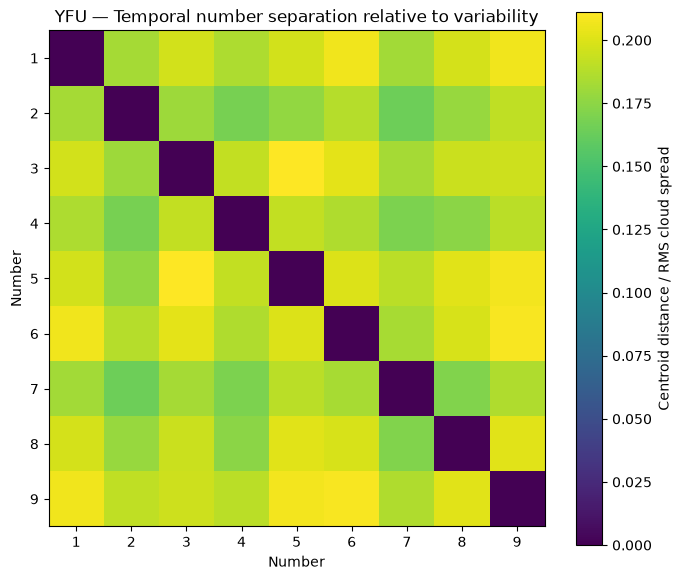

In [50]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Centroids and within-class RMS spread
centroids = {}
spreads = {}

for k in numbers_temporal:
    cloud = temporal_clouds[k]
    mu = cloud.mean(axis=0)

    centroids[k] = mu
    spreads[k] = np.sqrt(
        np.mean(np.sum((cloud - mu) ** 2, axis=1))
    )

# Pairwise separation-to-spread ratio
R = np.zeros((9, 9))

for i, k1 in enumerate(numbers_temporal):
    for j, k2 in enumerate(numbers_temporal):

        if i == j:
            continue

        distance = np.linalg.norm(
            centroids[k1] - centroids[k2]
        )

        pooled_spread = np.sqrt(
            (spreads[k1]**2 + spreads[k2]**2) / 2
        )

        R[i, j] = distance / pooled_spread

# Summarize the 36 number pairs
upper = np.triu_indices(9, k=1)
values = R[upper]

print("=== TEMPORAL CENTROID SEPARATION / CLOUD SPREAD ===")
print("Mean ratio:", round(values.mean(), 4))
print("Minimum:", round(values.min(), 4))
print("Maximum:", round(values.max(), 4))

# Heatmap
plt.figure(figsize=(7, 6))
plt.imshow(R, cmap="viridis", vmin=0)
plt.colorbar(label="Centroid distance / RMS cloud spread")
plt.xticks(range(9), numbers_temporal)
plt.yticks(range(9), numbers_temporal)
plt.xlabel("Number")
plt.ylabel("Number")
plt.title("YFU — Temporal number separation relative to variability")
plt.tight_layout()
plt.show()


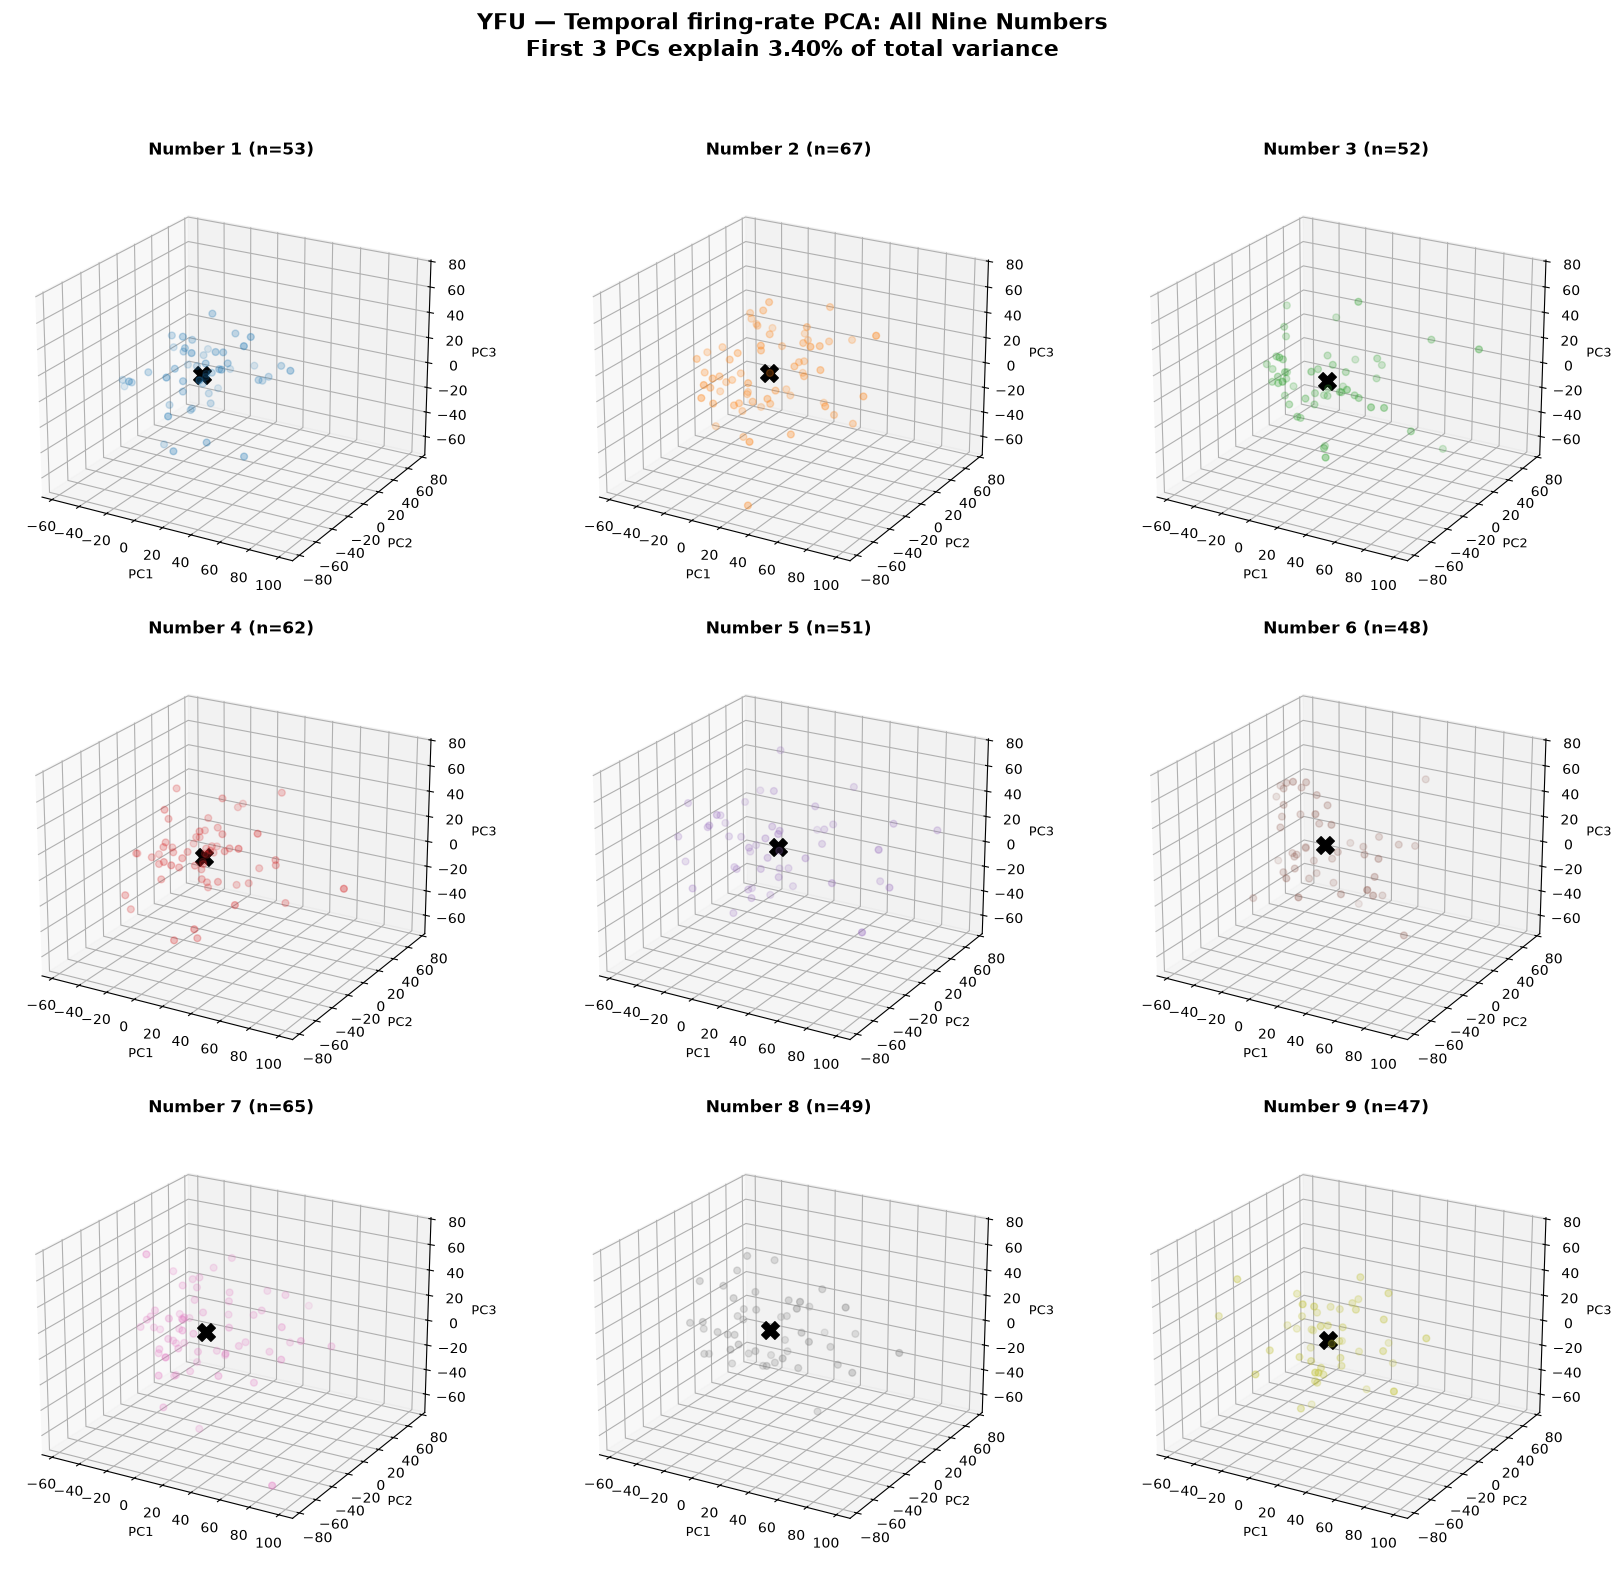

In [51]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Fit PCA once using all temporal presentations
pca = PCA(n_components=3)
Z = pca.fit_transform(X_temporal)

colors = plt.cm.tab10(np.arange(9))

# Shared axis limits
limits = [
    (Z[:, d].min(), Z[:, d].max())
    for d in range(3)
]

fig = plt.figure(figsize=(17, 16))

for idx, k in enumerate(numbers_temporal):

    ax = fig.add_subplot(
        3, 3, idx + 1, projection="3d"
    )

    points = Z[y_temporal == k]
    centroid = points.mean(axis=0)

    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        color=colors[idx],
        alpha=0.6,
        s=24
    )

    # Number centroid
    ax.scatter(
        *centroid,
        color="black",
        marker="X",
        s=160,
        depthshade=False
    )

    ax.set_xlim(*limits[0])
    ax.set_ylim(*limits[1])
    ax.set_zlim(*limits[2])

    ax.set_title(
        f"Number {k} (n={len(points)})",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("PC1", fontsize=9)
    ax.set_ylabel("PC2", fontsize=9)
    ax.set_zlabel("PC3", fontsize=9)

    ax.view_init(elev=22, azim=-60)

fig.suptitle(
    "YFU — Temporal firing-rate PCA: All Nine Numbers\n"
    f"First 3 PCs explain "
    f"{pca.explained_variance_ratio_.sum()*100:.2f}% "
    "of total variance",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


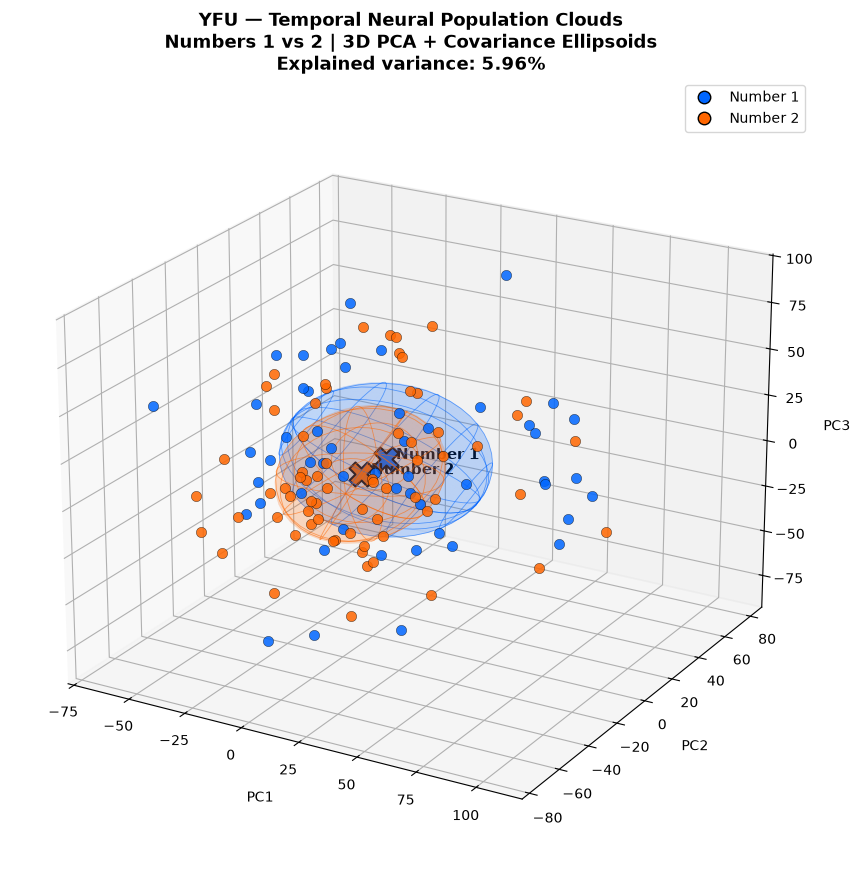

=== NUMBERS 1 VS 2 ===
Number 1 presentations: 53
Number 2 presentations: 67
Centroid distance (3D): 11.353
Number 1 RMS spread: 62.6618
Number 2 RMS spread: 58.0196
Separation / spread: 0.188


In [52]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D

# ============================================
# 1. Select numbers 1 and 2
# ============================================

selected_numbers = [1, 2]

mask = np.isin(y_temporal, selected_numbers)

X_pair = X_temporal[mask]
y_pair = y_temporal[mask]

# Fit a common PCA to both clouds
pca = PCA(n_components=3)
Z = pca.fit_transform(X_pair)

# High-contrast colors
colors = {
    1: "#0066FF",   # Strong blue
    2: "#FF6600"    # Bright orange
}

# ============================================
# 2. Function to draw a covariance ellipsoid
# ============================================

def plot_ellipsoid(ax, points, color, scale=1.0):

    mu = points.mean(axis=0)
    cov = np.cov(points, rowvar=False)

    eigenvalues, eigenvectors = np.linalg.eigh(cov)

    eigenvalues = np.maximum(eigenvalues, 0)

    # Ellipsoid surface
    u = np.linspace(0, 2*np.pi, 40)
    v = np.linspace(0, np.pi, 25)

    x = np.outer(np.cos(u), np.sin(v))
    y = np.outer(np.sin(u), np.sin(v))
    z = np.outer(np.ones_like(u), np.cos(v))

    sphere = np.stack(
        [x.ravel(), y.ravel(), z.ravel()]
    )

    transform = (
        eigenvectors
        @ np.diag(scale * np.sqrt(eigenvalues))
    )

    ellipsoid = transform @ sphere
    ellipsoid += mu[:, None]

    X_e = ellipsoid[0].reshape(x.shape)
    Y_e = ellipsoid[1].reshape(y.shape)
    Z_e = ellipsoid[2].reshape(z.shape)

    ax.plot_surface(
        X_e, Y_e, Z_e,
        color=color,
        alpha=0.12,
        linewidth=0,
        shade=False
    )

    ax.plot_wireframe(
        X_e, Y_e, Z_e,
        color=color,
        alpha=0.55,
        linewidth=0.6,
        rstride=4,
        cstride=4
    )

# ============================================
# 3. Plot overlapping clouds and ellipsoids
# ============================================

fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(111, projection="3d")

for k in selected_numbers:

    points = Z[y_pair == k]
    color = colors[k]

    # Individual neural responses
    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        color=color,
        s=55,
        alpha=0.85,
        edgecolors="black",
        linewidths=0.3,
        depthshade=False
    )

    # Covariance ellipsoid
    plot_ellipsoid(
        ax,
        points,
        color,
        scale=1.0
    )

    # Centroid
    mu = points.mean(axis=0)

    ax.scatter(
        *mu,
        color=color,
        marker="X",
        s=300,
        edgecolor="black",
        linewidth=1.5,
        depthshade=False
    )

    ax.text(
        *mu,
        f"  Number {k}",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xlabel("PC1", labelpad=10)
ax.set_ylabel("PC2", labelpad=10)
ax.set_zlabel("PC3", labelpad=10)

ax.set_title(
    "YFU — Temporal Neural Population Clouds\n"
    "Numbers 1 vs 2 | 3D PCA + Covariance Ellipsoids\n"
    f"Explained variance: "
    f"{pca.explained_variance_ratio_.sum()*100:.2f}%",
    fontsize=13,
    fontweight="bold"
)

ax.view_init(elev=22, azim=-60)

legend_elements = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor=colors[k],
           markeredgecolor="black",
           markersize=9,
           label=f"Number {k}")
    for k in selected_numbers
]

ax.legend(handles=legend_elements, loc="upper right")

plt.tight_layout()
plt.show()

# ============================================
# 4. Numerical centroid separation
# ============================================

P1 = Z[y_pair == 1]
P2 = Z[y_pair == 2]

mu1 = P1.mean(axis=0)
mu2 = P2.mean(axis=0)

distance = np.linalg.norm(mu1 - mu2)

spread1 = np.sqrt(
    np.mean(np.sum((P1 - mu1)**2, axis=1))
)

spread2 = np.sqrt(
    np.mean(np.sum((P2 - mu2)**2, axis=1))
)

pooled_spread = np.sqrt(
    (spread1**2 + spread2**2) / 2
)

print("=== NUMBERS 1 VS 2 ===")
print("Number 1 presentations:", len(P1))
print("Number 2 presentations:", len(P2))
print("Centroid distance (3D):", round(distance, 4))
print("Number 1 RMS spread:", round(spread1, 4))
print("Number 2 RMS spread:", round(spread2, 4))
print("Separation / spread:", round(distance / pooled_spread, 4))


=== SINGLE-NEURON NUMBER TUNING ===


,neuron,preferred_number,peak_rate_Hz,minimum_rate_Hz,modulation_index
0,0,5,4.8366,3.6201,0.1439
1,1,2,15.4229,13.6961,0.0593
2,2,1,10.0419,9.1489,0.0465
3,3,5,17.4292,15.2778,0.0658
4,4,8,0.2494,0.0629,0.5973
...,...,...,...,...,...
73,73,7,9.0085,7.6596,0.0809
74,74,8,6.3492,5.5556,0.0667
75,75,2,7.3466,6.1111,0.0918
76,76,3,6.1325,5.1474,0.0873



Preferred-number counts:
preferred_number
1     9
2    10
3    11
4     4
5    12
6     3
7     3
8    18
9     8
Name: count, dtype: int64


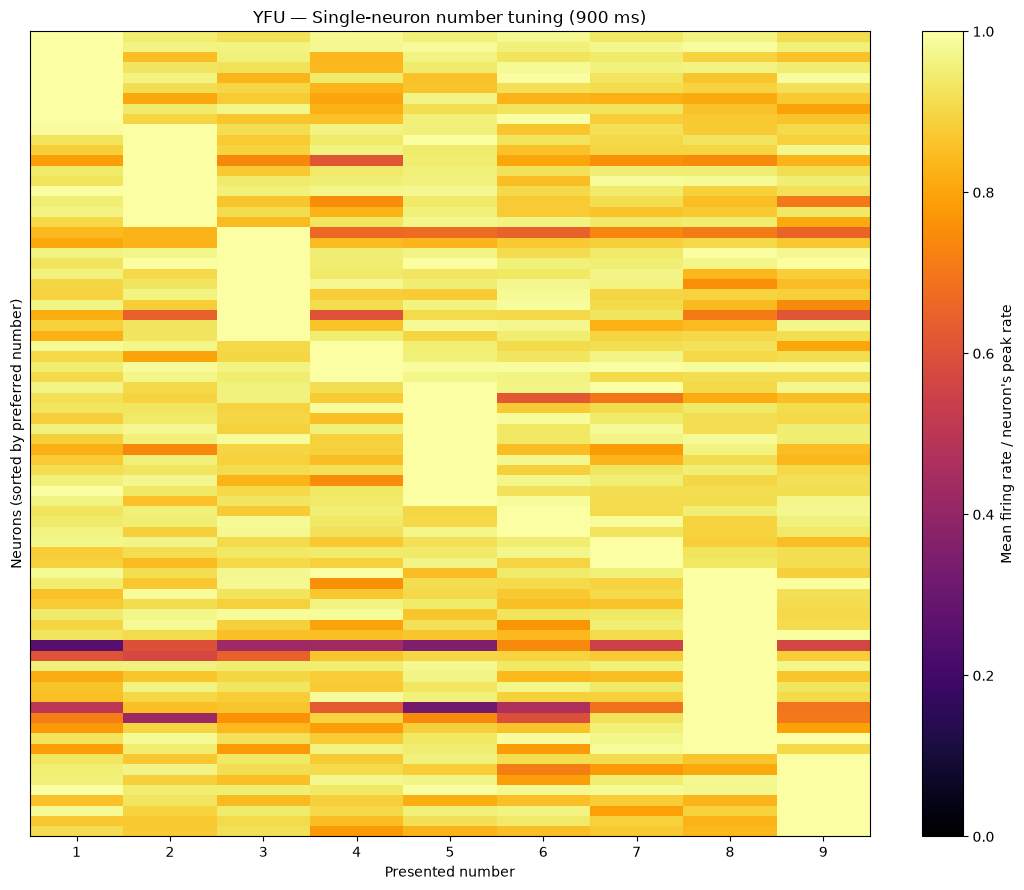

In [53]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================
# STEP 48: SINGLE-NEURON NUMBER TUNING
# ==============================================

# Original spike counts: 494 presentations x 78 neurons
# Convert 900 ms spike counts to firing rates (Hz)
X_rates = X / 0.9

# Mean firing rate for each number and neuron
# Shape: 9 numbers x 78 neurons
tuning_matrix = np.vstack([
    X_rates[y == k].mean(axis=0)
    for k in numbers
])

# Preferred number = number with maximum mean firing rate
preferred_numbers = numbers[
    np.argmax(tuning_matrix, axis=0)
]

# Peak and minimum firing rates
peak_rates = tuning_matrix.max(axis=0)
minimum_rates = tuning_matrix.min(axis=0)

# Descriptive modulation index
modulation_index = (
    (peak_rates - minimum_rates) /
    (peak_rates + minimum_rates + 1e-12)
)

tuning_summary = pd.DataFrame({
    "neuron": np.arange(X.shape[1]),
    "preferred_number": preferred_numbers,
    "peak_rate_Hz": peak_rates,
    "minimum_rate_Hz": minimum_rates,
    "modulation_index": modulation_index
})

print("=== SINGLE-NEURON NUMBER TUNING ===")
display(tuning_summary.round(4))

print("\nPreferred-number counts:")
print(
    tuning_summary["preferred_number"]
    .value_counts()
    .sort_index()
)

# ==============================================
# Plot number tuning heatmap
# ==============================================

# Normalize each neuron by its own peak response
normalized_tuning = (
    tuning_matrix /
    np.maximum(tuning_matrix.max(axis=0), 1e-12)
)

# Sort neurons by their preferred number
order = np.argsort(preferred_numbers)

plt.figure(figsize=(11, 9))

plt.imshow(
    normalized_tuning[:, order].T,
    aspect="auto",
    cmap="inferno",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Mean firing rate / neuron's peak rate")

plt.xticks(range(9), numbers)
plt.yticks([])

plt.xlabel("Presented number")
plt.ylabel("Neurons (sorted by preferred number)")
plt.title("YFU — Single-neuron number tuning (900 ms)")

plt.tight_layout()
plt.show()


In [55]:

import numpy as np
import pandas as pd
from scipy.stats import kruskal, false_discovery_control

# ==============================================
# STEP 49: SINGLE-NEURON NUMBER SELECTIVITY
# ==============================================

results = []

for j in range(X_rates.shape[1]):

    groups = [
        X_rates[y == k, j]
        for k in numbers
    ]

    H, p = kruskal(*groups)

    results.append({
        "neuron": j,
        "preferred_number": preferred_numbers[j],
        "peak_rate_Hz": peak_rates[j],
        "modulation_index": modulation_index[j],
        "H_statistic": H,
        "p_value": p
    })

selectivity_df = pd.DataFrame(results)

# Benjamini-Hochberg FDR correction
selectivity_df["p_fdr"] = false_discovery_control(
    selectivity_df["p_value"].to_numpy(),
    method="bh"
)

selectivity_df["significant_fdr"] = (
    selectivity_df["p_fdr"] < 0.05
)

selectivity_df = selectivity_df.sort_values(
    "p_value"
).reset_index(drop=True)

print("=== NUMBER SELECTIVITY: KRUSKAL-WALLIS ===")
print("Total neurons:", len(selectivity_df))

print(
    "Nominal p < 0.05:",
    (selectivity_df["p_value"] < 0.05).sum()
)

print(
    "FDR-significant neurons:",
    selectivity_df["significant_fdr"].sum()
)

display(selectivity_df.round(5))

# Save results
output_file = (
    ROOT / "tables1" /
    "YFU_single_neuron_number_selectivity.csv"
)

selectivity_df.to_csv(output_file, index=False)

print("Saved:", output_file)


=== NUMBER SELECTIVITY: KRUSKAL-WALLIS ===
Total neurons: 78
Nominal p < 0.05: 4
FDR-significant neurons: 0


,neuron,preferred_number,peak_rate_Hz,modulation_index,H_statistic,p_value,p_fdr,significant_fdr
0,61,3,2.82051,0.21333,19.51387,0.01234,0.52893,False
1,69,1,13.45912,0.07594,19.22397,0.01371,0.52893,False
2,33,9,8.88889,0.11708,18.12015,0.02034,0.52893,False
3,19,8,10.34014,0.10313,16.33179,0.03787,0.69957,False
4,42,3,7.30769,0.09545,14.80895,0.06297,0.69957,False
...,...,...,...,...,...,...,...,...
73,59,2,3.48259,0.08062,3.03900,0.93189,0.95869,False
74,26,8,3.49206,0.07810,2.80658,0.94590,0.95869,False
75,8,6,4.65278,0.05716,2.65388,0.95417,0.95869,False
76,6,4,25.28674,0.02733,2.64348,0.95470,0.95869,False


Saved: c:\Users\shafi\number-simplex-reproduction\tables1\YFU_single_neuron_number_selectivity.csv


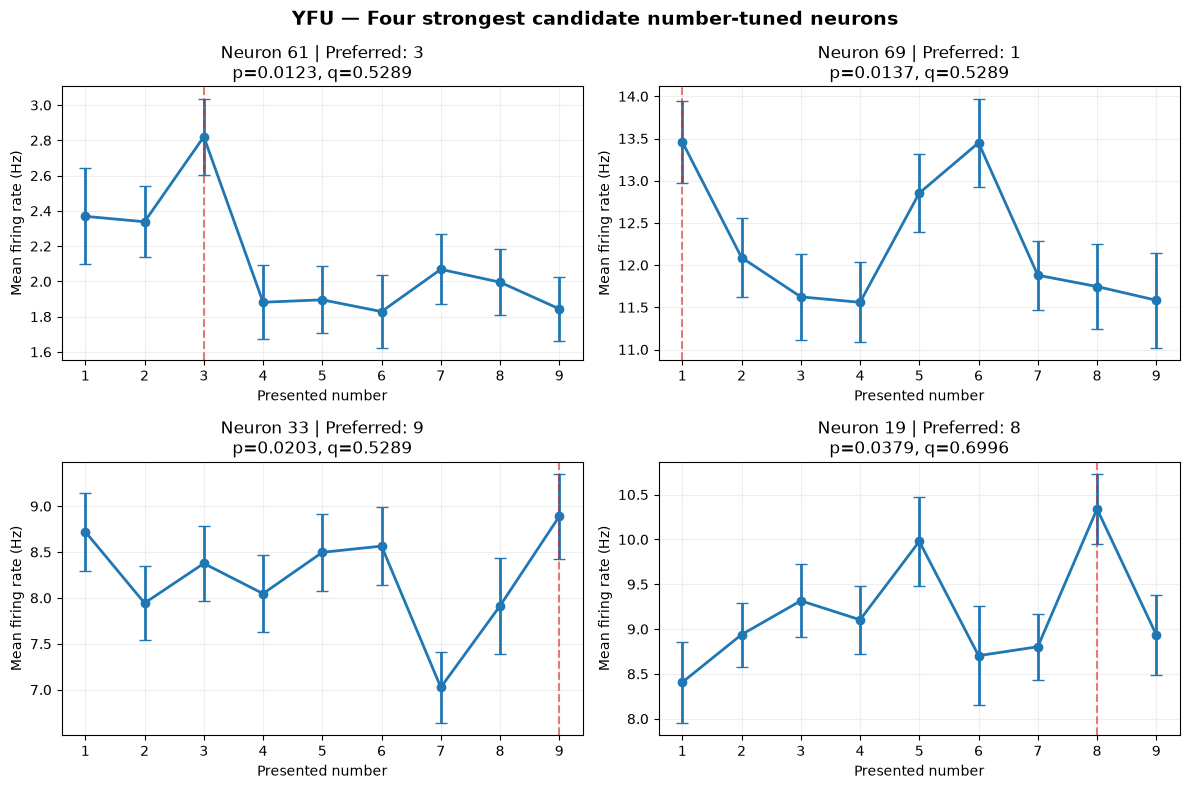

: 

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Four neurons with smallest Kruskal-Wallis p-values
top_neurons = selectivity_df.head(4)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, top_neurons.iterrows()):

    j = int(row["neuron"])

    means = np.array([
        X_rates[y == k, j].mean()
        for k in numbers
    ])

    sems = np.array([
        X_rates[y == k, j].std(ddof=1) /
        np.sqrt(np.sum(y == k))
        for k in numbers
    ])

    ax.errorbar(
        numbers,
        means,
        yerr=sems,
        marker="o",
        linewidth=2,
        capsize=4,
        color="tab:blue"
    )

    ax.axvline(
        row["preferred_number"],
        color="tab:red",
        linestyle="--",
        alpha=0.6
    )

    ax.set_title(
        f"Neuron {j} | Preferred: {int(row['preferred_number'])}\n"
        f"p={row['p_value']:.4f}, q={row['p_fdr']:.4f}"
    )

    ax.set_xlabel("Presented number")
    ax.set_ylabel("Mean firing rate (Hz)")
    ax.set_xticks(numbers)
    ax.grid(alpha=0.2)

plt.suptitle(
    "YFU — Four strongest candidate number-tuned neurons",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()
